# Hyperion — trajectory and verification

**Edit inputs → review choices → Run All → read the results and plots here.**

This notebook contains the Python model, its explanations, and its executed
outputs. It follows the selected rocket through rigid-body **6DOF / RK45**
ascent, separation, parking-orbit coast, restart, and finite departure burn.
It also performs the **19 assigned analyses through five calculations**.

Jump to [inputs](#inputs), [model](#model), [run and results](#results),
[flight plots](#plots), [departure](#departure), [engineering checks](#engineering),
[verification](#verification), or [remaining work](#remaining-work).

The shared verification workbook remains authoritative. A passing numerical
screen is not a closed requirement. Provisional aero geometry, engine-off
control limitations, and the departure-energy shortfall remain visible.

Open this notebook from the repository root and choose **Run → Run All Cells**.
Long definition cells can be collapsed. Inputs, model explanations, run cells
and saved results are grouped by function in this notebook.


In [1]:
from __future__ import annotations

import copy
import hashlib
import inspect
import json
import math
import re
import tomllib
from datetime import datetime, timezone
from html import escape
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import HTML, display
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy.spatial.transform import Rotation

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

ROOT = Path.cwd().resolve()
NOTEBOOK_PATH = ROOT / "Hyperion.ipynb"
INPUTS = ROOT / "inputs"
REPOSITORY_ROOT = ROOT
DEFAULT_CONFIG = INPUTS
if not NOTEBOOK_PATH.is_file() or not (INPUTS / "vehicle.toml").is_file():
    raise RuntimeError("Open Hyperion.ipynb with the repository root as the working directory.")

G0 = 9.80665  # Standard gravity, m/s².
MU = 3.986004418e14  # Earth gravitational parameter, m³/s².
RE = 6371000.0  # Spherical Earth radius, m.
OMEGA = np.array([0.0, 0.0, 7.292115e-5])  # Earth rotation, rad/s.
CALCULATIONS = ("flight_summary", "integrated_tmi", "lambert_window", "sourced_sizing", "thrust_sum")


<a id="inputs"></a>
## 1. Inputs and choices

| File | Change here |
|---|---|
| [vehicle.toml](inputs/vehicle.toml) | Dimensions, dry and loaded masses, engines, tanks, gimbals and aero interpretation |
| [flight.toml](inputs/flight.toml) | Launch, atmosphere/wind, guidance, throttle, staging, solver and departure target |
| [verification.toml](inputs/verification.toml) | Assigned activities, engineering inputs, acceptance rules and optional studies |
| [aerodynamics.csv](inputs/aerodynamics.csv) | The Mach/AoA coefficient and center-of-pressure table |
| [reference.json](inputs/reference.json) | Imported requirement text, orbital vectors, source references, reviewed evidence and follow-up work |

The tables below show the actual values used. Shared references such as
`{ref = "vehicle.stages.1.startup_propellant_kg"}` read their owning input
once; they are not duplicate physical settings. Change the owning input
and rerun the notebook. No input is optimized or resized automatically.


In [2]:
def load_reference(path=None):
    """Read the imported source bundle; never modify a shared-drive workbook."""
    return _read_json(_folder(path) / "reference.json")

def _folder(path=None):
    path = Path(path) if path is not None else INPUTS
    return path if path.is_dir() else path.parent


def _read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8-sig"))


def _documents(path=None):
    folder = _folder(path)
    documents = {}
    for name in ("vehicle", "flight", "verification"):
        with (folder / f"{name}.toml").open("rb") as stream:
            documents[name] = tomllib.load(stream)
    return documents, load_reference(folder)["mission_cases"]


def _context(documents, mission_cases):
    context = {}
    for name in ("vehicle", "flight"):
        for key, value in documents[name].items():
            if key == "choices":
                continue
            if key in context:
                raise ValueError(f"Input section {key!r} is defined in two files")
            context[key] = value
    context["checks"] = documents["verification"]
    context["mission_cases"] = mission_cases
    return context


def _at_path(context, path):
    value = context
    try:
        for part in path.split("."):
            value = value[int(part)] if isinstance(value, list) else value[part]
    except (KeyError, IndexError, TypeError, ValueError) as error:
        raise ValueError(f"Unknown input reference: {path}") from error
    return value


def _resolve(value, context, chain=()):
    if isinstance(value, dict):
        if "ref" in value:
            if set(value) - {"ref", "scale"}:
                raise ValueError("An input reference may only contain ref and scale")
            path = value["ref"]
            if not isinstance(path, str):
                raise ValueError("An input reference must be a dotted text path")
            if path in chain:
                raise ValueError(f"Circular input reference: {' -> '.join((*chain, path))}")
            result = _resolve(_at_path(context, path), context, (*chain, path))
            if "scale" in value:
                if isinstance(result, bool) or not isinstance(result, (int, float)):
                    raise ValueError(f"Scaled reference {path} must be numeric")
                scale = value["scale"]
                if isinstance(scale, bool) or not isinstance(scale, (int, float)):
                    raise ValueError(f"Scale for {path} must be numeric")
                result *= scale
            return result
        return {key: _resolve(item, context, chain) for key, item in value.items()}
    if isinstance(value, list):
        return [_resolve(item, context, chain) for item in value]
    return copy.deepcopy(value)


def load_config(path=None):
    """Return a fresh flight dictionary from vehicle.toml and flight.toml.

    ``path`` may select an inputs directory or either TOML file in it. Explicit
    JSON files remain supported for small independent tests and old run records.
    Aerodynamic paths are relative to the repository root, as in the model.
    """
    if path is not None and Path(path).suffix.lower() == ".json":
        return _read_json(path)
    documents, mission_cases = _documents(path)
    context = _context(documents, mission_cases)
    config = {
        key: _resolve(value, context)
        for key, value in context.items()
        if key not in {"checks", "mission_cases", "departure"}
    }
    for stage in config["vehicle"]["stages"]:
        total = stage["propellant_kg"]
        tank_total = sum(tank["loaded_mass_kg"] for tank in stage["tanks"])
        if not math.isclose(total, tank_total, rel_tol=1e-10, abs_tol=1e-6):
            raise ValueError(
                f"{stage['name']}: propellant_kg ({total:g} kg) must equal the "
                f"sum of tank loaded_mass_kg ({tank_total:g} kg). Update both "
                "the stage total and tank component masses in inputs/vehicle.toml."
            )
    return config


def load_checks(path=None):
    """Return calculation settings and activity-specific acceptance rules.

    Activity entries remain separate from calculation defaults so an activity
    override cannot silently change other checks. Studies and examples are not
    submitted as verification evidence. An explicit legacy JSON file is accepted.
    """
    if path is not None and Path(path).suffix.lower() == ".json":
        return _read_json(path)
    documents, mission_cases = _documents(path)
    context = _context(documents, mission_cases)
    checks = documents["verification"]
    calculations = checks.get("calculations", {})
    activities = checks.get("activities", {})
    duplicate = calculations.keys() & activities.keys()
    if duplicate:
        raise ValueError(f"Duplicate calculation/activity names: {sorted(duplicate)}")
    return _resolve({**calculations, **activities}, context)


def load_mission_cases(path=None):
    """Read the sourced orbital state vectors and their provenance."""
    if path is not None and Path(path).suffix.lower() == ".json":
        return _read_json(path)
    return load_reference(path)["mission_cases"]


def load_study(name, path=None):
    """Return a named study's inputs, choices and basis from verification.toml."""
    documents, mission_cases = _documents(path)
    studies = documents["verification"].get("studies", {})
    if name not in studies:
        raise KeyError(f"Unknown study {name!r}; choose from {', '.join(studies)}")
    return _resolve(studies[name], _context(documents, mission_cases))


def _leaves(value, path=""):
    """Keep numeric schedules in one readable row; expand records into rows."""
    if isinstance(value, dict) and "ref" not in value:
        for key, item in value.items():
            yield from _leaves(item, f"{path}.{key}" if path else key)
    elif isinstance(value, list) and any(isinstance(item, dict) for item in value):
        for index, item in enumerate(value):
            yield from _leaves(item, f"{path}.{index}")
    else:
        yield path, value


def _display(value):
    if isinstance(value, list):
        return "; ".join(str(item) for item in value)
    if isinstance(value, bool):
        return "Yes" if value else "No"
    return value


def _units(path):
    key = path.rsplit(".", 1)[-1]
    for suffix, units in (
        ("km2_s2", "km²/s²"), ("deg_s2", "deg/s²"), ("rad_s", "rad/s"),
        ("deg_s", "deg/s"), ("kg_m3", "kg/m³"), ("m3_s2", "m³/s²"),
        ("m_s", "m/s"), ("m2", "m²"), ("m3", "m³"), ("Nm", "N m"),
        ("nm", "N m"), ("kg", "kg"), ("deg", "deg"), ("mm", "mm"),
        ("Pa", "Pa"), ("pa", "Pa"), ("K", "K"), ("N", "N"),
        ("n", "N"), ("m", "m"), ("s", "s"), ("g", "g"),
        ("days", "days"),
    ):
        if key.endswith("_" + suffix):
            return units
    return "—"


def input_tables(path=None):
    """Return grouped tables of every editable setting, resolved before display.

    Each row names the saved key and its file. Reused values also show their
    reference, so the table identifies which definition should be edited.
    Sourced orbital vectors have their own file, outside the editable tables.
    """
    documents, mission_cases = _documents(path)
    context = _context(documents, mission_cases)
    tables = {}
    for filename, document in documents.items():
        for section, settings in document.items():
            if section == "choices":
                continue
            rows = []
            for key, raw in _leaves(settings, section):
                resolved = _resolve(raw, context)
                source = f"inputs/{filename}.toml → {key}"
                if isinstance(raw, dict) and "ref" in raw:
                    source += f" (uses {raw['ref']}"
                    source += f" × {raw['scale']}" if "scale" in raw else ""
                    source += ")"
                # Reused records are expanded too: hidden JSON is never a value.
                for subkey, value in _leaves(resolved, key):
                    rows.append({"Input": subkey, "Value": _display(value),
                                 "Units": _units(subkey), "Source": source})
            tables[f"{filename}: {section.replace('_', ' ').title()}"] = pd.DataFrame(
                rows, columns=["Input", "Value", "Units", "Source"]
            )
    return tables


def choices_table(path=None):
    """Show selected values directly from saved inputs, alongside their basis."""
    documents, mission_cases = _documents(path)
    context = _context(documents, mission_cases)
    rows = []
    for document in documents.values():
        for choice in document.get("choices", []):
            selections = []
            for path in choice["values"]:
                value = _resolve(_at_path(context, path), context)
                units = _units(path)
                suffix = f" {units}" if units != "—" else ""
                selections.append(f"{path.rsplit('.', 1)[-1]}: {_display(value)}{suffix}")
            rows.append({"Choice": choice["label"],
                         "Selection": "; ".join(selections), "Basis": choice["basis"]})
    return pd.DataFrame(rows, columns=["Choice", "Selection", "Basis"])


In [3]:
def show_input_tables(groups):
    """Show every input without making long tables dominate the notebook.

    This notebook shows their main settings above this expandable reference.
    No rows or columns are truncated here.
    """
    for title, table in groups.items():
        owner = str(title).split(":", 1)[0]
        source = (
            f' &middot; <a href="inputs/{owner}.toml">Edit {owner}.toml</a>'
            if owner in {"vehicle", "flight", "verification"}
            else ""
        )
        body = table.to_html(index=False, escape=True, max_rows=None, max_cols=None)
        display(
            HTML(
                f"<details><summary><strong>{escape(str(title))}</strong> "
                f"({len(table)} rows){source}</summary>{body}</details>"
            )
        )


def show_table(table):
    """Display a complete table, including long source and missing-input text."""
    display(HTML(table.to_html(index=False, escape=True, max_rows=None, max_cols=None)))


In [4]:
config = load_config()
checks = load_checks()
departure_inputs = checks["integrated_tmi"]["inputs"]
review = load_study("flight_review")
refinement_settings = load_study("solver_refinement")
departure_targets = load_study("departure_targets")

main_inputs = [
    ("Payload", config["vehicle"]["payload_kg"], "kg"),
    ("Diameter", config["vehicle"]["diameter_m"], "m"),
    ("Length", sum(stage["length_m"] for stage in config["vehicle"]["stages"]), "m"),
    ("Selected fairing length", config["vehicle"]["fairing_length_m"], "m"),
    ("Wind at reference height", config["atmosphere"]["wind_reference_m_s"], "m/s"),
    ("Target parking altitude", config["guidance"]["target_altitude_m"] / 1000, "km"),
    ("Axial acceleration limit", config["limits"]["axial_g"], "g"),
    ("Lateral acceleration limit", config["limits"]["lateral_g"], "g"),
    ("AoA goal at maximum Qα", review["max_qalpha_aoa_deg"], "deg"),
    ("Required control / aero moment", config["limits"]["control_ratio"], "ratio"),
    ("Coast before restart", departure_inputs["coast_duration_s"], "s"),
    ("Restart propellant", departure_inputs["restart_propellant_kg"], "kg"),
    ("Departure C3 target", departure_inputs["target_c3_km2_s2"], "km²/s²"),
]
show_table(pd.DataFrame(main_inputs, columns=["Input", "Value", "Units"]).round(4))

stage_columns = {
    "name": "Stage", "dry_mass_kg": "Dry mass (kg)",
    "propellant_kg": "Loaded propellant (kg)", "thrust_N": "Thrust (N)",
    "isp_s": "Isp (s)", "gimbal_limit_deg": "Gimbal travel (deg)",
    "gimbal_rate_deg_s": "Gimbal rate (deg/s)",
}
show_table(pd.DataFrame(config["vehicle"]["stages"])[list(stage_columns)]
           .rename(columns=stage_columns).round(3))
show_input_tables(input_tables())


Input,Value,Units
Payload,4313.0000,kg
Diameter,5.4000,m
Length,58.7630,m
Selected fairing length,11.5000,m
Wind at reference height,7.6200,m/s
Target parking altitude,200.0000,km
Axial acceleration limit,6.0000,g
Lateral acceleration limit,2.0000,g
AoA goal at maximum Qα,4.0000,deg
Required control / aero moment,2.0000,ratio


Stage,Dry mass (kg),Loaded propellant (kg),Thrust (N),Isp (s),Gimbal travel (deg),Gimbal rate (deg/s)
Stage 1,28518.455,422704.567,6765000,350,5.0,5.0
Stage 2,7898.353,66123.849,890000,451,5.0,5.0


Input,Value,Units,Source
vehicle.diameter_m,5.4,m,inputs/vehicle.toml → vehicle.diameter_m
vehicle.payload_kg,4313,kg,inputs/vehicle.toml → vehicle.payload_kg
vehicle.fairing_kg,2155.27825,kg,inputs/vehicle.toml → vehicle.fairing_kg
vehicle.fairing_length_m,11.5,m,inputs/vehicle.toml → vehicle.fairing_length_m
vehicle.payload_cg_above_fairing_base_m,4.5,m,inputs/vehicle.toml → vehicle.payload_cg_above_fairing_base_m
vehicle.payload_length_m,6.0,m,inputs/vehicle.toml → vehicle.payload_length_m
vehicle.payload_radius_m,1.5,m,inputs/vehicle.toml → vehicle.payload_radius_m
vehicle.fairing_cg_above_base_m,6.5,m,inputs/vehicle.toml → vehicle.fairing_cg_above_base_m
vehicle.payload_station_m,51.763013,m,inputs/vehicle.toml → vehicle.payload_station_m
vehicle.stages.0.name,Stage 1,—,inputs/vehicle.toml → vehicle.stages.0.name


Input,Value,Units,Source
aero.file,inputs/aerodynamics.csv,—,inputs/vehicle.toml → aero.file
aero.reference_area_m2,22.90221,m²,inputs/vehicle.toml → aero.reference_area_m2
aero.cp_station_offset_m,0.0,m,inputs/vehicle.toml → aero.cp_station_offset_m
aero.cp_units,inches converted to m,—,inputs/vehicle.toml → aero.cp_units
aero.cp_datum,nose; RASAero-format inference,—,inputs/vehicle.toml → aero.cp_datum
aero.outside_domain_policy,endpoint hold AND flag every sample,—,inputs/vehicle.toml → aero.outside_domain_policy
aero.post_separation_policy,reuse full vehicle coefficients; unvalidated proxy,—,inputs/vehicle.toml → aero.post_separation_policy


Input,Value,Units,Source
description,Hyperion 28 Oct 2026 synced sizing geometry; selected low-AoA 6DOF RK45 guidance.,—,inputs/flight.toml → description


...

Input,Value,Units,Source
assignments.0.activity_id,MIS.0.01.A01,—,inputs/verification.toml → assignments.0.activity_id
assignments.0.calculation,integrated_tmi,—,inputs/verification.toml → assignments.0.calculation
assignments.0.expected_activity,Integrated trajectory simulation from launch to TMI.,—,inputs/verification.toml → assignments.0.expected_activity
assignments.0.artifact,"Integrated ascent, coast and TMI simulation model",—,inputs/verification.toml → assignments.0.artifact
assignments.0.coverage,Finite-burn departure energy and propellant screen. Prograde guidance does not establish an Earth–Mars encounter or injection-vector accuracy.,—,inputs/verification.toml → assignments.0.coverage
assignments.1.activity_id,MIS.0.01.A02,—,inputs/verification.toml → assignments.1.activity_id
assignments.1.calculation,lambert_window,—,inputs/verification.toml → assignments.1.calculation
assignments.1.expected_activity,Earth-Mars Lambert launch-window sweep.,—,inputs/verification.toml → assignments.1.expected_activity
assignments.1.artifact,Lambert launch-window and departure-geometry model,—,inputs/verification.toml → assignments.1.artifact
assignments.1.coverage,"Three supplied state pairs. A daily launch-window sweep, launch-site access and optimization remain planned.",—,inputs/verification.toml → assignments.1.coverage


Input,Value,Units,Source
shared.minimum_liftoff_thrust_to_weight,1.2,—,inputs/verification.toml → shared.minimum_liftoff_thrust_to_weight


Input,Value,Units,Source
calculations.flight_summary.basis,Current integrated 6DOF ascent; provisional aero/actuator/geometry inputs. No qualification claim.,—,inputs/verification.toml → calculations.flight_summary.basis
calculations.lambert_window.basis,Three source Horizons samples; no daily launch-window optimization or site-access proof.,—,inputs/verification.toml → calculations.lambert_window.basis
calculations.lambert_window.inputs.cases.0.departure_label,2033-04-27 00:00 TDB,—,inputs/verification.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.arrival_label,2034-01-26 00:00 TDB,—,inputs/verification.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.time_of_flight_s,23673600.0,s,inputs/verification.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.departure_position_m,-120881146339.1056; -82360653324.81117; -35699389120.235855,m,inputs/verification.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.arrival_position_m,151893899759.2209; 144802306802.2028; 62324284364.44935,m,inputs/verification.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.departure_planet_velocity_m_s,17276.96831291071; -22058.20300105831; -9560.256841566952,m/s,inputs/verification.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.arrival_planet_velocity_m_s,-16526.05562522464; 17003.911452690558; 8244.829125552214,m/s,inputs/verification.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.long_way,Yes,—,inputs/verification.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)


Input,Value,Units,Source
activities.PERF.2.05.A01.basis,Requirement numeric screen only; model-validation and open source conflicts remain.,—,inputs/verification.toml → activities.PERF.2.05.A01.basis
activities.PERF.2.05.A01.acceptance.0.metric,liftoff_thrust_to_weight,—,inputs/verification.toml → activities.PERF.2.05.A01.acceptance.0.metric
activities.PERF.2.05.A01.acceptance.0.operator,>=,—,inputs/verification.toml → activities.PERF.2.05.A01.acceptance.0.operator
activities.PERF.2.05.A01.acceptance.0.limit,1.2,—,inputs/verification.toml → activities.PERF.2.05.A01.acceptance.0.limit (uses checks.shared.minimum_liftoff_thrust_to_weight)
activities.PERF.2.05.A01.acceptance.0.units,1,—,inputs/verification.toml → activities.PERF.2.05.A01.acceptance.0.units
activities.PERF.2.05.A01.acceptance.0.source,PERF.2.05,—,inputs/verification.toml → activities.PERF.2.05.A01.acceptance.0.source
activities.PERF.2.06.A01.basis,Requirement numeric screen only; model-validation and open source conflicts remain.,—,inputs/verification.toml → activities.PERF.2.06.A01.basis
activities.PERF.2.06.A01.acceptance.0.metric,max_axial_g,—,inputs/verification.toml → activities.PERF.2.06.A01.acceptance.0.metric
activities.PERF.2.06.A01.acceptance.0.operator,<=,—,inputs/verification.toml → activities.PERF.2.06.A01.acceptance.0.operator
activities.PERF.2.06.A01.acceptance.0.limit,6.0,—,inputs/verification.toml → activities.PERF.2.06.A01.acceptance.0.limit (uses limits.axial_g)


Input,Value,Units,Source
studies.departure_targets.basis,Compare the sourced master case with the provisional verification target using the same coast/restart inputs. An energy screen does not prove a Mars intercept.,—,inputs/verification.toml → studies.departure_targets.basis
studies.departure_targets.targets.0.label,Master source case,—,inputs/verification.toml → studies.departure_targets.targets.0.label
studies.departure_targets.targets.0.target_c3_km2_s2,7.7058,km²/s²,inputs/verification.toml → studies.departure_targets.targets.0.target_c3_km2_s2 (uses mission.target_C3_km2_s2)
studies.departure_targets.targets.1.label,Verification target under review,—,inputs/verification.toml → studies.departure_targets.targets.1.label
studies.departure_targets.targets.1.target_c3_km2_s2,9.8,km²/s²,inputs/verification.toml → studies.departure_targets.targets.1.target_c3_km2_s2 (uses departure.target_c3_km2_s2)
studies.flight_review.max_qalpha_aoa_deg,4.0,deg,inputs/verification.toml → studies.flight_review.max_qalpha_aoa_deg
studies.flight_review.basis,User design goal at max-Qalpha; separate from the guidance AoA command limit.,—,inputs/verification.toml → studies.flight_review.basis
studies.solver_refinement.enabled,No,—,inputs/verification.toml → studies.solver_refinement.enabled
studies.solver_refinement.rtol_scale,0.1,—,inputs/verification.toml → studies.solver_refinement.rtol_scale
studies.solver_refinement.max_step_scale,0.5,—,inputs/verification.toml → studies.solver_refinement.max_step_scale


In [5]:
show_table(choices_table())
print("Departure basis:", checks["integrated_tmi"]["basis"])
print("Solver sensitivity enabled:", refinement_settings["enabled"])


Choice,Selection,Basis
Vehicle geometry,fairing_length_m: 11.5 m; diameter_m: 5.4 m,Selected sizing geometry. The master Payload sheet still gives a 14 m fairing; reconcile with CAD and the aero export.
CP interpretation,cp_units: inches converted to m; cp_datum: nose; RASAero-format inference,Inches are tentative user confirmation; datum is inferred and remains unverified.
Aerodynamic reference,reference_area_m2: 22.902210444669596 m²; outside_domain_policy: endpoint hold AND flag every sample; post_separation_policy: reuse full vehicle coefficients; unvalidated proxy,Source export geometry is unverified. Flag out-of-domain and separated-vehicle proxy samples.
Stage 1 control capability,gimbal_limit_deg: 5.0 deg; gimbal_rate_deg_s: 5.0 deg/s,"Assumed actuator capability, not approved hardware performance."
Stage 2 control capability,gimbal_limit_deg: 5.0 deg; gimbal_rate_deg_s: 5.0 deg/s,"Assumed actuator capability, not approved hardware performance."
Departure baseline,coast_duration_s: 600 s; restart_propellant_kg: 301.843504114127 kg; target_c3_km2_s2: 9.8 km²/s²,The verification target is provisional. The master target is retained as a separate comparison case; neither is a solved encounter.
Integrator,method: RK45; rtol: 2e-07; max_step_s: 0.4 s,Quaternion rigid-body 6DOF with discrete stage and fairing events; no flexible dynamics.
Atmosphere and wind,wind_reference_m_s: 7.62 m/s; wind_toward_deg_east_of_north: 90.0; temperature_offset_K: 0.0 K; density_scale: 1.0,Layered standard atmosphere and a deterministic wind profile; no measured launch sounding.
Coast and roll control,rcs_moment_Nm: 0.0 N m; roll_rcs_moment_Nm: 0.0 N m; control_ratio: 2.0,Evaluate all phases. No central-axis TVC roll authority is available.
Actuator response,actuator_time_constant_s: 0.15 s,Assumed first-order response; requires hardware confirmation.


Departure basis: The saved coast and restart debit are screening assumptions. Shared 6DOF prograde TMI; no Mars encounter targeting.
Solver sensitivity enabled: False


**Read the choices before interpreting the plots.** The selected fairing is
11.5 m although another source gives 14 m. CP is provisionally interpreted
as inches from the nose; the export geometry remains unconfirmed. The full
vehicle aero table is reused after staging and flagged as a proxy. Gimbal
hardware and deterministic wind are assumptions, not qualified performance.

The active departure target is C3 = 9.8 km²/s². The master comparison case is
retained separately. The vehicle input file defines the selected hardware. No sizing changes occur
during simulation.


<a id="model"></a>
## 2. Model conventions and equations

SI units are used internally. Position and velocity are Earth-centered inertial
(ECI); body +x points from engine to nose. The quaternion **[x, y, z, w]**
rotates body vectors into ECI. Earth co-rotation is included at release.

The 22 integrated states are position (3), velocity (3), quaternion (4), body
angular rates (3), stage propellant masses (2), gimbal angles (2), and five
delta-v/loss integrals. In compact form:

$$\dot{\mathbf r}=\mathbf v,\qquad
\dot{\mathbf v}=\mathbf g+(\mathbf F_T+\mathbf F_A)/m.$$

Rigid-body angular dynamics include changing inertia, exhaust angular-momentum
flux, aerodynamic torque and control torque. The model shifts the tracked
center of mass when mass is shed. It does not model structural bending,
slosh, ignition shock, navigation errors, or an Earth–Mars intercept.


In [6]:
def unit(v):
    """Normalize a vector; leave a zero vector at zero."""
    return v / max(np.linalg.norm(v), 1e-15)


def matrix(q):
    """Return the body-to-ECI rotation for an [x, y, z, w] quaternion."""
    x, y, z, w = q / np.linalg.norm(q)
    return np.array(
        [
            [1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)],
            [2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
            [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)],
        ]
    )


def quaternion_derivative(q, w):
    """Quaternion rate from body-axis angular velocity ``w`` in rad/s."""
    return 0.5 * np.r_[q[3] * w + np.cross(q[:3], w), -np.dot(q[:3], w)]


def local_frame(r):
    """Return east, north and radial-up unit vectors at ECI position ``r``."""
    up = unit(r)
    east = unit(np.cross([0.0, 0.0, 1.0], up))
    north = np.cross(up, east)
    return east, north, up


### Atmosphere and wind

Temperature lapse layers provide temperature, pressure, density, sound speed
and viscosity versus geometric altitude. The chosen wind profile rotates with
Earth. Mach and AoA use velocity relative to this moving air; inertial velocity
is used for orbital energy. Temperature and density offsets remain editable.


In [7]:
class Atmosphere:
    """US Standard Atmosphere 1976 lower layers; explicit upper extension.

    Uses geopotential height, hydrostatic pressure and ideal gas. Above 86 km
    a continuous isothermal exponential tail is a SCREENING approximation.
    Wind is a configurable deterministic profile, not a launch-day forecast.
    """

    def __init__(self, c):
        self.c = c
        self.h = np.array([0, 11000, 20000, 32000, 47000, 51000, 71000, 84852.0])
        self.lapse = np.array([-0.0065, 0, 0.001, 0.0028, 0, -0.0028, -0.002])
        self.tb = [288.15]
        self.pb = [101325.0]
        for i, lapse_rate in enumerate(self.lapse):
            layer_height = self.h[i + 1] - self.h[i]
            base_temperature = self.tb[-1]
            self.tb.append(base_temperature + lapse_rate * layer_height)
            self.pb.append(
                self.pb[-1]
                * (
                    np.exp(-G0 * layer_height / (287.05287 * base_temperature))
                    if lapse_rate == 0
                    else (
                        (base_temperature + lapse_rate * layer_height)
                        / base_temperature
                    )
                    ** (-G0 / (287.05287 * lapse_rate))
                )
            )

    def sample(self, h):
        """Return temperature, pressure, density, sound speed and viscosity.

        ``h`` is geometric altitude in metres. Returned units are K, Pa, kg/m³,
        m/s and Pa·s, respectively. Layer equations use geopotential altitude.
        """
        geometric_height = max(0.0, h)
        geopotential_height = 6356766 * geometric_height / (6356766 + geometric_height)
        if geopotential_height <= self.h[-1]:
            layer = min(
                6,
                max(0, np.searchsorted(self.h, geopotential_height, side="right") - 1),
            )
            lapse_rate = self.lapse[layer]
            base_temperature = self.tb[layer]
            height_in_layer = geopotential_height - self.h[layer]
            temperature = base_temperature + lapse_rate * height_in_layer
            pressure = self.pb[layer] * (
                np.exp(-G0 * height_in_layer / (287.05287 * base_temperature))
                if lapse_rate == 0
                else (temperature / base_temperature)
                ** (-G0 / (287.05287 * lapse_rate))
            )
        else:
            temperature = self.tb[-1]
            pressure = self.pb[-1] * np.exp(
                -G0 * (geopotential_height - self.h[-1]) / (287.05287 * temperature)
            )
        temperature += self.c.get("temperature_offset_K", 0.0)
        rho = pressure / (287.05287 * temperature) * self.c.get("density_scale", 1.0)
        sound_speed = np.sqrt(1.4 * 287.05287 * temperature)
        viscosity = (
            1.716e-5
            * (temperature / 273.15) ** 1.5
            * (273.15 + 110.4)
            / (temperature + 110.4)
        )
        return temperature, pressure, rho, sound_speed, viscosity

    def wind(self, h, t, r):
        """Return the wind vector in ECI (m/s), including the optional gust."""
        config = self.c
        east, north, _ = local_frame(r)
        speed = (
            config["wind_reference_m_s"]
            * (max(h, 0.0) / config["wind_reference_height_m"])
            ** config["wind_exponent"]
        )
        speed = min(
            speed,
            config["wind_reference_m_s"]
            * (config["wind_cap_height_m"] / config["wind_reference_height_m"])
            ** config["wind_exponent"],
        )
        # Taper above the user-selected atmosphere region; avoid permanent wind in space.
        speed *= np.clip(
            (config["wind_zero_height_m"] - h)
            / max(1.0, config["wind_zero_height_m"] - config["wind_taper_height_m"]),
            0,
            1,
        )
        direction = np.deg2rad(config["wind_toward_deg_east_of_north"])
        gust = config.get("gust_amplitude_m_s", 0.0) * np.sin(
            2 * np.pi * t / config.get("gust_period_s", 12.0)
        )
        return (speed + gust) * np.cos(direction) * north + (speed + gust) * np.sin(
            direction
        ) * east


### Aerodynamic lookup

The CSV is interpolated in Mach and AoA to obtain axial/normal coefficients
and CP. Coefficients are projected consistently between wind and body axes.
Values outside the supplied domain use its endpoint and are flagged.
Those flags remain in the output; endpoint holding does not validate the model
outside the table. Dynamic pressure is **Q = ½ρV²** and **Qα uses degrees**.


In [8]:
class AeroTable:
    """Interpolate each Mach curve, then interpolate between AoA curves.

    Missing coverage uses the nearest endpoint and sets a flag in the result.
    The same full-stack table is reused after separation as an explicit proxy.
    """

    def __init__(self, path, c):
        self.c = c
        table = np.genfromtxt(path, delimiter=",", names=True, encoding="utf-8-sig")
        self.alpha = np.unique(table["alpha_deg"])
        self.cols = {}
        self.mins = []
        self.maxs = []
        for angle in self.alpha:
            rows = table[table["alpha_deg"] == angle]
            rows = np.sort(rows, order="mach")
            self.cols[angle] = rows
            self.mins.append(rows["mach"].min())
            self.maxs.append(rows["mach"].max())
        self.mlo = max(self.mins)
        self.mhi = min(self.maxs)

    def sample(self, mach, alpha, powered):
        """Return (axial coefficient, normal coefficient, CP metres, range flag).

        ``alpha`` is in radians; CP is measured back from the nose. ``powered``
        chooses the engine-on or engine-off axial coefficient column.
        """
        alpha_deg = abs(np.rad2deg(alpha))
        outside_table = mach < self.mlo or mach > self.mhi or alpha_deg > self.alpha[-1]
        # Endpoint holding is always flagged in output; never claimed as interpolation.
        lookup_mach = np.clip(mach, self.mlo, self.mhi)
        lookup_alpha = np.clip(alpha_deg, self.alpha[0], self.alpha[-1])
        coefficients = []
        for column in ["ca_on" if powered else "ca_off", "cn", "cp_from_nose_m"]:
            values_at_each_alpha = [
                np.interp(
                    lookup_mach, self.cols[angle]["mach"], self.cols[angle][column]
                )
                for angle in self.alpha
            ]
            coefficients.append(
                float(np.interp(lookup_alpha, self.alpha, values_at_each_alpha))
            )
        # CN must vanish at zero AoA for the symmetric rigid-body extension.
        if alpha_deg < 1e-10:
            coefficients[1] = 0.0
        return *coefficients, outside_table


### Mass, center of mass, and inertia

Dry stages, payload and fairing use simplified rigid shapes. Each tank's liquid
is a shrinking equivalent cylindrical column. Combining their masses and
stations gives center of mass and principal inertias throughout the burn.
Loaded propellant includes residual and startup inventories. Startup debits
supply no thrust impulse; residuals remain aboard until the stage is shed.


In [9]:
class Vehicle:
    """Mass, axial centre of mass and principal inertia from simple components."""

    def __init__(self, c):
        self.c = c
        self.s = c["stages"]
        self.offset = [0.0, self.s[0]["length_m"]]

    def properties(self, props, attached, fairing):
        """Return mass (kg), CM station (m) and [roll, pitch, yaw] inertia (kg·m²).

        Stations remain measured from the original vehicle base after separation.
        ``props`` holds the two remaining propellant inventories; ``attached``
        and ``fairing`` select the components that still travel with the payload.
        """
        components = []
        radius = self.c["diameter_m"] / 2
        for i, stage in enumerate(self.s):
            if i == 0 and not attached:
                continue
            stage_base = self.offset[i]
            dry_length = stage["length_m"] - (
                self.c["fairing_length_m"] if i == 1 else 0.0
            )
            components.append(
                (
                    stage["dry_mass_kg"],
                    stage_base + 0.5 * dry_length,
                    dry_length,
                    radius,
                )
            )
            remaining_fraction = np.clip(props[i] / stage["propellant_kg"], 0.0, 1.0)
            for tank in stage["tanks"]:
                # Equivalent constant-area liquid column drains downward. Slosh omitted.
                liquid_height = tank["height_m"] * remaining_fraction
                components.append(
                    (
                        tank["loaded_mass_kg"] * remaining_fraction,
                        stage_base + tank["bottom_m"] + 0.5 * liquid_height,
                        liquid_height,
                        radius,
                    )
                )
        base = self.offset[1] + self.s[1]["length_m"] - self.c["fairing_length_m"]
        components.append(
            (
                self.c["payload_kg"],
                base + self.c["payload_cg_above_fairing_base_m"],
                self.c["payload_length_m"],
                self.c["payload_radius_m"],
            )
        )
        if fairing:
            components.append(
                (
                    self.c["fairing_kg"],
                    base + self.c["fairing_cg_above_base_m"],
                    self.c["fairing_length_m"],
                    radius,
                )
            )
        total = sum(x[0] for x in components)
        cg = sum(m * x for m, x, L, r in components) / total
        # Equivalent uniform solid cylinders + parallel-axis theorem.
        roll_inertia = sum(0.5 * m * r * r for m, x, L, r in components)
        transverse_inertia = sum(
            m * (3 * r * r + L * L) / 12 + m * (x - cg) ** 2
            for m, x, L, r in components
        )
        return (
            total,
            cg,
            np.array([roll_inertia, transverse_inertia, transverse_inertia]),
        )


### Guidance, control, and rigid-body forces

The following class initializes the vehicle, sets its guidance direction, and
evaluates all 22 derivatives. Its numbered comments follow air-relative loads,
thrust/throttle limits, attitude feedback, gimbal response and moving-mass
dynamics. The commanded axial cap and minimum throttle are applied together;
the resulting acceleration is checked afterward against the selected limits.

Aerodynamic moment, demanded tracking moment and available control moment are
separate quantities. Engine-off phases are included in control checks.


In [10]:
class RigidBodyModel:
    def __init__(self, c=None, root=None):
        c = copy.deepcopy(load_config() if c is None else c)
        self.c = c
        self.root = Path(root) if root is not None else REPOSITORY_ROOT
        self.atm = Atmosphere(c["atmosphere"])
        if c["solver"].get("method", "RK45") != "RK45":
            raise ValueError("This simulator requires method=RK45.")
        if c["solver"]["max_time_s"] <= 0:
            raise ValueError("max_time_s must be positive.")
        for st in c["vehicle"]["stages"]:
            if not 0 <= st["residual_kg"] < st["propellant_kg"]:
                raise ValueError("Propellant must exceed residual inventory.")
            if not 0 < st["min_throttle"] <= 1:
                raise ValueError("Minimum throttle must be in (0,1].")
        self.vehicle = Vehicle(c["vehicle"])
        self.table = AeroTable(self.root / c["aero"]["file"], c["aero"])
        self.events = []
        self.rows = []
        self.phase = 1
        self.attached = True
        self.fairing = True
        self.cutoff = False
        self.ignition_time = 0.0

    def initial(self):
        """Build the release state, including Earth rotation and startup propellant."""
        lat, lon = np.deg2rad(
            [self.c["launch"]["latitude_deg"], self.c["launch"]["longitude_deg"]]
        )
        props = [s["propellant_kg"] for s in self.c["vehicle"]["stages"]]
        props[0] -= self.c["vehicle"]["stages"][0]["startup_propellant_kg"]
        initial_cg = self.vehicle.properties(props, True, True)[1]
        r = (RE + self.c["launch"]["altitude_m"] + initial_cg) * np.array(
            [np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)]
        )
        e, n, u = local_frame(r)
        q = Rotation.from_matrix(np.column_stack([u, e, n])).as_quat()
        # Start at release with launch vehicle co-rotating with the Earth.
        return np.r_[
            r,
            np.cross(OMEGA, r),
            q,
            OMEGA @ matrix(q),
            props,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
        ]

    def guidance(self, t, r, vrel, v, h, qbar):
        """Return the desired body-axis direction in ECI.

        The first stage follows the pitch schedule. The upper stage targets
        altitude while building orbital speed. An air-relative AoA limit relaxes
        as dynamic pressure falls. Inputs use seconds, SI vectors and pascals.
        """
        guidance = self.c["guidance"]
        east, north, up = local_frame(r)
        azimuth = np.deg2rad(self.c["launch"]["azimuth_deg"])
        horizontal = np.sin(azimuth) * east + np.cos(azimuth) * north
        pitch = np.deg2rad(
            np.interp(t, guidance["pitch_time_s"], guidance["pitch_deg"])
        )
        if self.phase == 2:
            # Altitude hold with radial-velocity damping while building orbital speed.
            radial_speed = np.dot(v, up)
            horizontal_speed = np.linalg.norm(v - radial_speed * up)
            radial_acceleration = np.clip(
                guidance["altitude_gain_s2"] * (guidance["target_altitude_m"] - h)
                - guidance["vertical_damping_s"] * radial_speed,
                -12.0,
                12.0,
            )
            mass = self.vehicle.properties(self._props, self.attached, self.fairing)[0]
            thrust = self.c["vehicle"]["stages"][1]["thrust_N"]
            pitch_sine = np.clip(
                (
                    MU / np.linalg.norm(r) ** 2
                    - horizontal_speed * horizontal_speed / np.linalg.norm(r)
                    + radial_acceleration
                )
                / (thrust / mass),
                -0.7,
                0.95,
            )
            pitch = np.arcsin(pitch_sine)
        target = np.cos(pitch) * horizontal + np.sin(pitch) * up
        if (
            t > guidance.get("aoa_limit_start_s", 25.0)
            and qbar > 1.0
            and np.linalg.norm(vrel) > 100
            and np.dot(vrel, horizontal) > 0
        ):
            air_velocity_direction = unit(vrel)
            angle = np.arccos(np.clip(np.dot(target, air_velocity_direction), -1, 1))
            # Continuous relaxation as atmosphere thins; avoids a command step at max-Q exit.
            limit = np.deg2rad(
                min(
                    60.0,
                    guidance["aoa_command_limit_deg"]
                    * np.sqrt(max(1.0, guidance["aoa_limit_min_q_Pa"] / qbar)),
                )
            )
            if angle > limit:
                tangent = unit(
                    target
                    - air_velocity_direction * np.dot(target, air_velocity_direction)
                )
                target = (
                    np.cos(limit) * air_velocity_direction + np.sin(limit) * tangent
                )
        return unit(target)

    def evaluate(self, t, y, record=False):
        """Evaluate one state: return its RK45 derivative or a named output row.

        Steps follow the physical chain: air state, aerodynamic loads, thrust
        command, attitude control, actuator response, rigid-body dynamics, and
        payload loads. ``record=True`` exposes those intermediate quantities.
        """
        # 1. Recover the mass properties and air-relative state.
        config = self.c
        position = y[:3]
        velocity = y[3:6]
        body_to_eci = matrix(y[6:10])
        body_rate = y[10:13]
        propellant = np.maximum(y[13:15], 0)
        self._props = propellant
        mass, cg, inertia = self.vehicle.properties(
            propellant, self.attached, self.fairing
        )
        altitude = np.linalg.norm(position) - RE
        east, north, up = local_frame(position)
        temperature, pressure, rho, sound_speed, air_viscosity = self.atm.sample(
            altitude
        )
        wind = self.atm.wind(altitude, t, position)
        air_velocity = velocity - np.cross(OMEGA, position) - wind
        air_velocity_body = body_to_eci.T @ air_velocity
        speed = np.linalg.norm(air_velocity)
        mach = speed / sound_speed
        alpha = (
            np.arctan2(np.linalg.norm(air_velocity_body[1:]), air_velocity_body[0])
            if speed > 1e-5
            else 0.0
        )
        qbar = 0.5 * rho * speed**2
        powered = self.phase in [1, 2] and not self.cutoff
        ca, cn, cp_from_nose, outside_table = self.table.sample(mach, alpha, powered)
        # 2. Resolve aerodynamic force and its moment about the current CM.
        reference_area = config["aero"]["reference_area_m2"]
        normal_force = (
            -qbar * reference_area * cn * unit(np.r_[0.0, air_velocity_body[1:]])
            if np.linalg.norm(air_velocity_body[1:]) > 1e-10
            else np.zeros(3)
        )
        aero_force = np.r_[-qbar * reference_area * ca, 0.0, 0.0] + normal_force
        # The raw table describes the complete vehicle. Upper-stage reuse is explicit.
        nose = sum(s["length_m"] for s in config["vehicle"]["stages"])
        if not self.fairing:
            nose -= config["vehicle"]["fairing_length_m"]
        cp = nose - cp_from_nose + config["aero"].get("cp_station_offset_m", 0.0)
        aero_moment_body = np.cross(np.array([cp - cg, 0.0, 0.0]), aero_force)
        # 3. Apply the throttle schedule and CM axial-acceleration command cap.
        stage_index = 0 if self.phase == 1 else 1
        stage = config["vehicle"]["stages"][stage_index]
        engine = self.vehicle.offset[stage_index] + stage["engine_pivot_m"]
        arm = cg - engine
        full_thrust = stage["thrust_N"]
        # Optional known nozzle-area correction. Default zero because source lacks area.
        full_thrust = max(
            0.0,
            full_thrust
            + (stage["reference_pressure_Pa"] - pressure) * stage["exit_area_m2"],
        )
        throttle = 0.0
        if powered:
            schedule = np.interp(
                t, config["throttle"]["time_s"], config["throttle"]["fraction"]
            )
            axial_cap = (
                mass * G0 * config["limits"]["command_axial_g"] - aero_force[0]
            ) / max(full_thrust, 1.0)
            throttle = np.clip(min(schedule, axial_cap), stage["min_throttle"], 1.0)
        thrust = full_thrust * throttle
        # 4. Convert attitude error into a limited angular-acceleration command.
        target = self.guidance(t, position, air_velocity, velocity, altitude, qbar)
        target_body = body_to_eci.T @ target
        attitude_error = np.cross(np.array([1.0, 0.0, 0.0]), target_body)
        control = config["control"]
        natural_frequency = control["natural_frequency_rad_s"]
        earth_rate_body = body_to_eci.T @ OMEGA
        angular_command = (
            natural_frequency * natural_frequency * attitude_error
            - 2
            * control["damping_ratio"]
            * natural_frequency
            * (body_rate - earth_rate_body)
        )
        command_magnitude = np.linalg.norm(angular_command)
        angular_acceleration_limit = np.deg2rad(
            control.get("angular_acceleration_limit_deg_s2", 0.3)
        )
        if self.phase == 2:
            angular_acceleration_limit = np.deg2rad(
                control.get("upper_angular_acceleration_limit_deg_s2", 1.5)
            )
        if command_magnitude > angular_acceleration_limit:
            angular_command *= angular_acceleration_limit / command_magnitude
        # Axial roll is held by a separately stated RCS allocation, not engine gimbal.
        mdot = thrust / (stage["isp_s"] * G0) if powered else 0.0
        propellant_rate = np.zeros(2)
        propellant_rate[stage_index] = -mdot
        # Propellant flow changes CM and inertia; use one-kilogram differences.
        inertia_rate = np.zeros(3)
        cgdot = 0.0
        cgddot = 0.0
        if mdot:
            altered = propellant.copy()
            altered[stage_index] = max(0.0, altered[stage_index] - 1.0)
            minus = self.vehicle.properties(altered, self.attached, self.fairing)
            inertia_rate = (minus[2] - inertia) * mdot
            added_propellant = propellant.copy()
            added_propellant[stage_index] += 1.0
            plus = self.vehicle.properties(
                added_propellant, self.attached, self.fairing
            )
            cg_per_kg = (plus[1] - minus[1]) / 2
            cgdot = -cg_per_kg * mdot
            # Slow mass-flow variation: exact schedule slope or late-burn g-limit slope.
            knot = min(
                len(config["throttle"]["time_s"]) - 2,
                max(0, np.searchsorted(config["throttle"]["time_s"], t) - 1),
            )
            slope = (
                config["throttle"]["fraction"][knot + 1]
                - config["throttle"]["fraction"][knot]
            ) / (
                config["throttle"]["time_s"][knot + 1]
                - config["throttle"]["time_s"][knot]
            )
            mass_flow_derivative = (
                full_thrust * slope / (stage["isp_s"] * G0)
                if schedule < axial_cap and stage["min_throttle"] < throttle < 1
                else (
                    -mdot * config["limits"]["command_axial_g"] / stage["isp_s"]
                    if axial_cap < schedule and throttle > stage["min_throttle"]
                    else 0.0
                )
            )
            cgddot = (
                plus[1] - 2 * cg + minus[1]
            ) * mdot**2 - cg_per_kg * mass_flow_derivative
        exhaust_momentum_flux = mdot * arm * arm * np.r_[0.0, body_rate[1:]]
        required_moment = (
            inertia * angular_command
            + np.cross(body_rate, inertia * body_rate)
            + inertia_rate * body_rate
            + exhaust_momentum_flux
            - aero_moment_body
        )
        # 5. Allocate pitch/yaw moment to gimbal motion and roll to the stated RCS.
        gimbal_limit = np.deg2rad(stage["gimbal_limit_deg"])
        gimbal_rate_limit = np.deg2rad(stage["gimbal_rate_deg_s"])
        # State y[15:17] represents force-direction tilt in body y,z (radians).
        desired = (
            np.array([-required_moment[2], required_moment[1]]) / max(thrust * arm, 1.0)
            if thrust > 0 and arm > 0
            else np.zeros(2)
        )
        desired_magnitude = np.linalg.norm(desired)
        if desired_magnitude > np.sin(gimbal_limit):
            desired *= np.sin(gimbal_limit) / desired_magnitude
        desired = np.arcsin(np.clip(desired, -1.0, 1.0))
        gimbal_rate = (desired - y[15:17]) / control["actuator_time_constant_s"]
        if np.linalg.norm(gimbal_rate) > gimbal_rate_limit:
            gimbal_rate *= gimbal_rate_limit / np.linalg.norm(gimbal_rate)
        gimbal_angles = y[15:17].copy()
        gimbal_magnitude = np.linalg.norm(gimbal_angles)
        if gimbal_magnitude > gimbal_limit:
            gimbal_angles *= gimbal_limit / gimbal_magnitude
        thrust_force = (
            thrust
            * np.r_[
                np.sqrt(max(0.0, 1.0 - np.sum(np.sin(gimbal_angles) ** 2))),
                np.sin(gimbal_angles),
            ]
        )
        thrust_moment = np.cross(np.array([-arm, 0.0, 0.0]), thrust_force)
        rcs_capacity = (
            control["rcs_moment_Nm"] if not powered else control["roll_rcs_moment_Nm"]
        )
        rcs_moment = np.zeros(3)
        if not powered:
            required_magnitude = np.linalg.norm(required_moment)
            rcs_moment = required_moment * min(
                1.0, rcs_capacity / max(required_magnitude, 1e-12)
            )
        else:
            rcs_moment[0] = np.clip(required_moment[0], -rcs_capacity, rcs_capacity)
        # 6. Integrate translation and rotation, including changing inertia.
        angular_acceleration = (
            aero_moment_body
            + thrust_moment
            + rcs_moment
            - np.cross(body_rate, inertia * body_rate)
            - inertia_rate * body_rate
            - exhaust_momentum_flux
        ) / inertia
        gravity = -MU * position / np.linalg.norm(position) ** 3
        acceleration = body_to_eci @ (aero_force + thrust_force) / mass + gravity
        # 7. Compute payload-point proper acceleration and accumulated velocity losses.
        point = np.array([config["vehicle"]["payload_station_m"] - cg, 0.0, 0.0])
        proper = (
            (aero_force + thrust_force) / mass
            + np.cross(angular_acceleration, point)
            + np.cross(body_rate, np.cross(body_rate, point))
        )
        proper += 2 * np.cross(body_rate, np.array([-cgdot, 0.0, 0.0])) + np.array(
            [-cgddot, 0.0, 0.0]
        )
        velocity_direction = unit(velocity)
        steering = (
            thrust
            / mass
            * (
                1.0
                - np.clip(
                    np.dot(body_to_eci @ unit(thrust_force), velocity_direction), -1, 1
                )
            )
            if thrust
            else 0.0
        )
        gimbal_loss = (
            thrust / mass * (1.0 - thrust_force[0] / thrust) if thrust else 0.0
        )
        drag_loss = -np.dot(body_to_eci @ aero_force, velocity_direction) / mass
        grav_loss = -np.dot(gravity, velocity_direction)
        derivative = np.r_[
            velocity,
            acceleration,
            quaternion_derivative(y[6:10], body_rate),
            angular_acceleration,
            propellant_rate,
            gimbal_rate,
            thrust / mass,
            steering,
            gimbal_loss,
            drag_loss,
            grav_loss,
        ]
        if not record:
            return derivative
        available = thrust * max(arm, 0.0) * np.sin(gimbal_limit) + (
            control["rcs_moment_Nm"] if not powered else 0.0
        )
        aero_moment = np.linalg.norm(aero_moment_body[1:])
        demand = np.linalg.norm(required_moment[1:])
        relative = velocity - np.cross(OMEGA, position)

        def elevation(vector):
            return np.rad2deg(
                np.arctan2(
                    np.dot(vector, up), np.linalg.norm(vector - np.dot(vector, up) * up)
                )
            )

        inertial_speed = np.linalg.norm(velocity)
        radial = np.dot(velocity, up)
        angular_momentum = np.cross(position, velocity)
        eccentricity = np.linalg.norm(
            np.cross(velocity, angular_momentum) / MU - unit(position)
        )
        energy = 0.5 * inertial_speed**2 - MU / np.linalg.norm(position)
        semimajor_axis = -MU / (2 * energy) if energy < 0 else np.inf
        sample = dict(
            t_s=t,
            phase=self.phase,
            altitude_m=altitude,
            mass_kg=mass,
            cg_from_base_m=cg,
            Ixx_kg_m2=inertia[0],
            Iyy_kg_m2=inertia[1],
            Izz_kg_m2=inertia[2],
            prop1_kg=propellant[0],
            prop2_kg=propellant[1],
            cg_rate_m_s=cgdot,
            cg_acceleration_m_s2=cgddot,
            airspeed_m_s=speed,
            inertial_speed_m_s=inertial_speed,
            vertical_speed_m_s=radial,
            mach=mach,
            temperature_K=temperature,
            pressure_Pa=pressure,
            density_kg_m3=rho,
            wind_m_s=np.linalg.norm(wind),
            reynolds_length=rho
            * speed
            * (
                sum(s["length_m"] for s in config["vehicle"]["stages"])
                - (0.0 if self.attached else config["vehicle"]["stages"][0]["length_m"])
                - (0.0 if self.fairing else config["vehicle"]["fairing_length_m"])
            )
            / air_viscosity,
            q_Pa=qbar,
            alpha_deg=np.rad2deg(alpha),
            qalpha_Pa_deg=qbar * np.rad2deg(alpha),
            pitch_deg=elevation(body_to_eci[:, 0]),
            heading_deg=np.rad2deg(
                np.arctan2(
                    np.dot(body_to_eci[:, 0], east), np.dot(body_to_eci[:, 0], north)
                )
            )
            % 360,
            flight_path_deg=elevation(relative),
            inertial_flight_path_deg=elevation(velocity),
            command_pitch_deg=elevation(target),
            throttle=throttle,
            thrust_N=thrust,
            gimbal_y_deg=np.rad2deg(gimbal_angles[0]),
            gimbal_z_deg=np.rad2deg(gimbal_angles[1]),
            gimbal_total_deg=np.rad2deg(np.linalg.norm(gimbal_angles)),
            gimbal_rate_deg_s=np.rad2deg(np.linalg.norm(gimbal_rate)),
            axial_g=proper[0] / G0,
            lateral_g=np.linalg.norm(proper[1:]) / G0,
            cm_proper_g=np.linalg.norm(aero_force + thrust_force) / mass / G0,
            aero_moment_Nm=aero_moment,
            available_moment_Nm=available,
            required_moment_Nm=demand,
            actual_control_moment_Nm=np.linalg.norm((thrust_moment + rcs_moment)[1:]),
            moment_margin_Nm=available - aero_moment,
            ratio2_margin_Nm=available
            - config["limits"]["control_ratio"] * aero_moment,
            normal_force_N=np.linalg.norm(normal_force),
            axial_aero_force_N=-aero_force[0],
            cp_from_base_m=cp,
            aero_out_of_domain=int(outside_table),
            aero_configuration_proxy=int(not self.attached or not self.fairing),
            ideal_dv_m_s=y[17],
            steering_loss_m_s=y[18],
            gimbal_loss_m_s=y[19],
            drag_loss_m_s=y[20],
            gravity_loss_m_s=y[21],
            osculating_perigee_m=semimajor_axis * (1 - eccentricity) - RE,
            osculating_apogee_m=semimajor_axis * (1 + eccentricity) - RE,
            quaternion_norm=np.linalg.norm(y[6:10]),
        )
        for i, k in enumerate(["x", "y", "z"]):
            sample[f"eci_{k}_m"] = position[i]
            sample[f"eci_v{k}_m_s"] = velocity[i]
            sample[f"body_rate_{k}_deg_s"] = np.rad2deg(body_rate[i])
        for i, k in enumerate(["x", "y", "z", "w"]):
            sample[f"quaternion_{k}"] = y[6 + i]
        return sample


### RK45 and discrete events

RK45 advances each continuous phase with the saved tolerances. Stage burnout,
separation, fairing release and orbital cutoff are event boundaries. Mass,
center-of-mass position and velocity are mapped at each discontinuity before
restarting integration. Reporting samples include the event endpoints.
The physical derivatives above are shared by ascent and departure.


In [11]:
class Simulation(RigidBodyModel):
    def integrate(self, y, t0, t1, events=None):
        """Advance one continuous phase and sample its dense RK45 solution."""
        solver = self.c["solver"]
        if solver.get("verbose", False):
            print(f"Integrating phase {self.phase}: t={t0:.2f} s", flush=True)
        atol = np.r_[
            np.full(3, solver["position_atol_m"]),
            np.full(3, solver["velocity_atol_m_s"]),
            np.full(4, 1e-9),
            np.full(3, 1e-9),
            np.full(2, 1e-4),
            np.full(2, 1e-9),
            np.full(5, 1e-5),
        ]
        solution = solve_ivp(
            self.evaluate,
            (t0, t1),
            y,
            method="RK45",
            rtol=solver["rtol"],
            atol=atol,
            max_step=solver["max_step_s"],
            dense_output=True,
            events=events,
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        if solver.get("verbose", False):
            print(
                f"  reached {solution.t[-1]:.2f} s, {solution.nfev} RHS evaluations",
                flush=True,
            )
        sample_times = np.arange(t0, solution.t[-1], solver["output_step_s"])
        sample_times = np.unique(np.r_[sample_times, solution.t[-1]])
        self.rows.extend(
            self.evaluate(float(t), solution.sol(t), True) for t in sample_times
        )
        return solution.y[:, -1], float(solution.t[-1]), solution

    def run(self):
        """Run ascent phases, applying CM and velocity changes at mass shedding."""
        y = self.initial()
        t = 0.0
        config = self.c

        def burnout1(t, y):
            return y[13] - config["vehicle"]["stages"][0]["residual_kg"]

        burnout1.terminal = True
        burnout1.direction = -1

        def ground(t, y):
            return np.linalg.norm(y[:3]) - RE + 1.0

        ground.terminal = True
        ground.direction = -1
        self.events.append({"event": "liftoff", "t_s": 0.0})
        y, t, solution = self.integrate(
            y, t, config["solver"]["max_time_s"], [burnout1, ground]
        )
        if not len(solution.t_events[0]):
            self.events.append({"event": "terminated_before_stage1_burnout", "t_s": t})
            return self.rows, self.events
        self.phase = 0
        self.events.append({"event": "MECO", "t_s": t})
        y, t, coast_solution = self.integrate(
            y,
            t,
            min(t + config["separation"]["delay_s"], config["solver"]["max_time_s"]),
            [ground],
        )
        if len(coast_solution.t_events[0]) or t >= config["solver"]["max_time_s"]:
            self.events.append(
                {
                    "event": (
                        "ground_contact"
                        if len(coast_solution.t_events[0])
                        else "time_limit"
                    ),
                    "t_s": t,
                }
            )
            return self.rows, self.events
        mass_before, cg_before, _ = self.vehicle.properties(y[13:15], True, True)
        self.attached = False
        mass_after, cg_after, _ = self.vehicle.properties(y[13:15], False, True)
        shift = matrix(y[6:10]) @ np.array([cg_after - cg_before, 0.0, 0.0])
        y[:3] += shift
        y[3:6] += np.cross(matrix(y[6:10]) @ y[10:13], shift)
        separation_delta_v = config["separation"]["upper_delta_v_m_s"]
        y[3:6] += matrix(y[6:10])[:, 0] * separation_delta_v
        self.events.append(
            {
                "event": "stage_separation",
                "t_s": t,
                "shed_mass_kg": mass_before - mass_after,
                "cg_shift_m": cg_after - cg_before,
                "upper_delta_v_m_s": separation_delta_v,
                "lower_delta_v_m_s": -mass_after
                / (mass_before - mass_after)
                * separation_delta_v,
            }
        )
        self.phase = 2
        self.ignition_time = t
        cg_before = self.vehicle.properties(y[13:15], False, self.fairing)[1]
        y[14] -= config["vehicle"]["stages"][1]["startup_propellant_kg"]
        cg_after = self.vehicle.properties(y[13:15], False, self.fairing)[1]
        shift = matrix(y[6:10]) @ np.array([cg_after - cg_before, 0.0, 0.0])
        y[:3] += shift
        y[3:6] += np.cross(matrix(y[6:10]) @ y[10:13], shift)
        self.events.append({"event": "stage2_ignition", "t_s": t})

        def burnout2(t, y):
            return y[14] - config["vehicle"]["stages"][1]["residual_kg"]

        burnout2.terminal = True
        burnout2.direction = -1

        def insertion(t, y):
            r = y[:3]
            v = y[3:6]
            radial = np.dot(v, unit(r))
            vt = np.linalg.norm(v - radial * unit(r))
            return vt - np.sqrt(MU / np.linalg.norm(r))

        insertion.terminal = True
        insertion.direction = 1

        def fairing(t, y):
            return (
                np.linalg.norm(y[:3]) - RE - config["separation"]["fairing_altitude_m"]
            )

        fairing.terminal = True
        fairing.direction = 1
        event = "time_limit"
        while t < config["solver"]["max_time_s"]:
            if (
                self.fairing
                and np.linalg.norm(y[:3]) - RE
                >= config["separation"]["fairing_altitude_m"]
            ):
                before = self.vehicle.properties(y[13:15], False, True)
                self.fairing = False
                after = self.vehicle.properties(y[13:15], False, False)
                shift = matrix(y[6:10]) @ np.array([after[1] - before[1], 0.0, 0.0])
                y[:3] += shift
                y[3:6] += np.cross(matrix(y[6:10]) @ y[10:13], shift)
                self.events.append(
                    {
                        "event": "fairing_jettison",
                        "t_s": t,
                        "shed_mass_kg": before[0] - after[0],
                    }
                )
            phase_events = [burnout2, insertion, ground] + (
                [fairing] if self.fairing else []
            )
            y, t, solution = self.integrate(
                y, t, config["solver"]["max_time_s"], phase_events
            )
            if len(solution.t_events[0]):
                event = "stage2_propellant_limit"
                break
            if len(solution.t_events[1]):
                event = "orbital_speed_cutoff"
                break
            if len(solution.t_events[2]):
                event = "ground_contact"
                break
            if self.fairing and len(solution.t_events[3]):
                # Move across root by a negligible distance to execute mass jump next loop.
                y[:3] += unit(y[:3]) * 1e-6
                continue
            event = "time_limit"
            break
        self.events.append({"event": event, "t_s": t})
        if event == "orbital_speed_cutoff":
            self.phase = 3
            self.cutoff = True
            y, t, _ = self.integrate(
                y, t, t + config["guidance"]["post_cutoff_coast_s"], [ground]
            )
            self.events.append({"event": "end_coast", "t_s": t})
        return self.rows, self.events


def summarize(df, events, c):
    """Return the canonical engineering summary and sampled governing load cases."""
    peaks = {}
    for key in [
        "q_Pa",
        "qalpha_Pa_deg",
        "axial_g",
        "lateral_g",
        "normal_force_N",
        "axial_aero_force_N",
        "aero_moment_Nm",
        "required_moment_Nm",
        "thrust_N",
        "gimbal_total_deg",
    ]:
        row = df.loc[df[key].abs().idxmax()]
        peaks[key] = {
            k: float(row[k])
            for k in [
                "t_s",
                key,
                "altitude_m",
                "mach",
                "alpha_deg",
                "mass_kg",
                "aero_out_of_domain",
                "aero_configuration_proxy",
            ]
        }
    powered = df[df.thrust_N > 0]
    loaded = df[df.q_Pa > 100]
    active = df[df.aero_moment_Nm > 1.0]
    coast = df[df.thrust_N == 0]
    ratios = active.available_moment_Nm / active.aero_moment_Nm
    powered_ratios = (
        powered[powered.aero_moment_Nm > 1.0].available_moment_Nm
        / powered[powered.aero_moment_Nm > 1.0].aero_moment_Nm
    )
    cutoff = next(
        (x["t_s"] for x in events if x["event"] == "orbital_speed_cutoff"), None
    )
    end = df.iloc[-1] if cutoff is None else df.iloc[np.argmin(np.abs(df.t_s - cutoff))]
    orbit_ok = bool(
        cutoff is not None
        and abs(end.altitude_m - c["guidance"]["target_altitude_m"]) < 5000
        and abs(end.vertical_speed_m_s) < 30
        and end.osculating_perigee_m > 190000
    )
    stage2 = c["vehicle"]["stages"][1]
    burnout_mass = (
        stage2["dry_mass_kg"] + c["vehicle"]["payload_kg"] + stage2["residual_kg"]
    )
    reserve = (
        stage2["isp_s"]
        * G0
        * np.log(
            (stage2["dry_mass_kg"] + c["vehicle"]["payload_kg"] + end.prop2_kg)
            / burnout_mass
        )
    )
    checks = dict(
        axial_acceleration_pass=bool(df.axial_g.abs().max() <= c["limits"]["axial_g"]),
        lateral_acceleration_pass=bool(df.lateral_g.max() <= c["limits"]["lateral_g"]),
        nominal_moment_inequality_all_samples=bool(
            (df.moment_margin_Nm >= -1e-8).all()
        ),
        nominal_moment_ratio_requirement_all_samples=bool(
            (df.ratio2_margin_Nm >= -1e-8).all()
        ),
        moment_demand_within_capacity_powered=bool(
            (powered.required_moment_Nm <= powered.available_moment_Nm + 1e-6).all()
        ),
        circular_200km_target_screen_pass=orbit_ok,
        validated_control_authority=False,
    )
    # Rigid-body load cases: interface proper acceleration times supported payload.
    cases = []
    for name, key in [
        ("Max-Q", "q_Pa"),
        ("Max-Qalpha", "qalpha_Pa_deg"),
        ("Max axial acceleration", "axial_g"),
        ("Max lateral acceleration", "lateral_g"),
        ("Max aerodynamic moment", "aero_moment_Nm"),
        ("Max TVC demand", "required_moment_Nm"),
        ("Max thrust", "thrust_N"),
        ("Max aerodynamic normal force", "normal_force_N"),
        ("Max aerodynamic axial force", "axial_aero_force_N"),
    ]:
        row = df.loc[df[key].abs().idxmax()].to_dict()
        row["case"] = name
        row["payload_axial_force_N"] = row["axial_g"] * G0 * c["vehicle"]["payload_kg"]
        row["payload_lateral_force_N"] = (
            row["lateral_g"] * G0 * c["vehicle"]["payload_kg"]
        )
        cases.append(row)
    checks["significant_q_table_domain_pass"] = bool(
        (loaded.aero_out_of_domain == 0).all()
    )
    checks["powered_moment_ratio_requirement_pass"] = bool(
        (powered.ratio2_margin_Nm >= -1e-8).all()
    )
    summary = dict(
        peaks=peaks,
        checks=checks,
        events=events,
        duration_s=float(df.t_s.max()),
        initial_mass_kg=float(df.mass_kg.iloc[0]),
        ideal_remaining_delta_v_m_s=float(reserve),
        reference_TMI_delta_v_m_s=c.get("mission", {}).get("TMI_delta_v_m_s", 3570.5),
        min_moment_ratio_above_1Nm=float(ratios.min()) if len(ratios) else None,
        min_powered_moment_ratio_above_1Nm=(
            float(powered_ratios.min()) if len(powered_ratios) else None
        ),
        worst_ratio2_margin_Nm=float(df.ratio2_margin_Nm.min()),
        coast_peak_aero_moment_Nm=(
            float(coast.aero_moment_Nm.max()) if len(coast) else 0.0
        ),
        additional_coast_moment_for_ratio2_Nm=(
            float(
                np.maximum(
                    0,
                    coast.aero_moment_Nm * c["limits"]["control_ratio"]
                    - coast.available_moment_Nm,
                ).max()
            )
            if len(coast)
            else 0.0
        ),
        aero_outside_table_samples=int(df.aero_out_of_domain.sum()),
        aero_outside_table_above_100Pa_samples=int(loaded.aero_out_of_domain.sum()),
        post_separation_aero_proxy_samples=int(df.aero_configuration_proxy.sum()),
        separation_average_acceleration_g=c["separation"]["upper_delta_v_m_s"]
        / c["separation"]["impulse_duration_s"]
        / G0,
        peak_aero_outside_table_q_Pa=(
            float(df.loc[df.aero_out_of_domain == 1, "q_Pa"].max())
            if df.aero_out_of_domain.any()
            else 0.0
        ),
        cutoff_state={
            k: float(end[k])
            for k in [
                "t_s",
                "altitude_m",
                "inertial_speed_m_s",
                "vertical_speed_m_s",
                "osculating_perigee_m",
                "osculating_apogee_m",
                "prop2_kg",
                "ideal_dv_m_s",
                "steering_loss_m_s",
                "gimbal_loss_m_s",
                "drag_loss_m_s",
                "gravity_loss_m_s",
            ]
        },
        assumptions=c["assumptions"],
    )
    return summary, pd.DataFrame(cases)


def run_trajectory(config=None):
    """Run the shared model and return ``(trajectory, summary, simulation)``.

    ``config`` may be an editable dictionary or a JSON path. Omitting it loads
    the selected case from ``inputs/vehicle.toml`` and ``inputs/flight.toml``. Output samples
    include both sides of instantaneous phase/mass changes, so event times may
    repeat intentionally; do not silently discard those rows for load checks.
    Units appear in column names; ``mach`` and quaternions are dimensionless.
    ``simulation.load_cases`` contains sampled maximum-load rows.

    Numerical verification is distinct from engineering verification: the
    returned summary retains failed coast-control and aero-coverage checks.
    """
    if config is None or isinstance(config, (str, Path)):
        config = load_config(config)
    simulation = Simulation(config)
    rows, events = simulation.run()
    trajectory = pd.DataFrame(rows)
    summary, cases = summarize(trajectory, events, simulation.c)
    simulation.load_cases = cases
    return trajectory, summary, simulation


In [12]:
def flight_summary(context):
    """Extract requirement-facing measurements from one shared trajectory run.

    ``context`` is the tuple returned by ``run_trajectory()``. Result names carry units. Model assumptions and
    aerodynamic coverage are retained alongside the numerical measurements.
    """
    history, summary, simulation = context
    config = simulation.c
    powered = history[history.thrust_N > 0]
    result = {
        "payload_kg": config["vehicle"]["payload_kg"],
        "liftoff_mass_kg": float(history.mass_kg.iloc[0]),
        "installed_sea_level_thrust_N": config["vehicle"]["stages"][0]["thrust_N"],
        "liftoff_thrust_to_weight": float(
            history.thrust_N.iloc[0] / (history.mass_kg.iloc[0] * G0)
        ),
        "max_axial_g": float(history.axial_g.abs().max()),
        "max_lateral_g": float(history.lateral_g.abs().max()),
        "max_q_Pa": float(history.q_Pa.max()),
        "max_qalpha_Pa_deg": float(history.qalpha_Pa_deg.max()),
        "alpha_at_max_qalpha_deg": float(
            history.loc[history.qalpha_Pa_deg.idxmax(), "alpha_deg"]
        ),
        "minimum_control_ratio_margin_Nm": float(history.ratio2_margin_Nm.min()),
        "minimum_powered_control_ratio_margin_Nm": float(
            powered.ratio2_margin_Nm.min()
        ),
        "required_coast_control_Nm": summary["additional_coast_moment_for_ratio2_Nm"],
        "steering_loss_m_s": summary["cutoff_state"]["steering_loss_m_s"],
        "drag_loss_m_s": summary["cutoff_state"]["drag_loss_m_s"],
        "gravity_loss_m_s": summary["cutoff_state"]["gravity_loss_m_s"],
        "ideal_remaining_delta_v_m_s": summary["ideal_remaining_delta_v_m_s"],
        "length_m": sum(s["length_m"] for s in config["vehicle"]["stages"]),
        "diameter_m": config["vehicle"]["diameter_m"],
        "fineness_ratio": sum(s["length_m"] for s in config["vehicle"]["stages"])
        / config["vehicle"]["diameter_m"],
        "aero_outside_table_samples": summary["aero_outside_table_samples"],
        "aero_proxy_samples": summary["post_separation_aero_proxy_samples"],
        "events": simulation.events,
        "cutoff": summary["cutoff_state"],
        "assumptions": config["assumptions"],
    }
    for i, stage in enumerate(config["vehicle"]["stages"], 1):
        # Report actual integrated inventory rather than integrating discontinuities.
        result[f"stage{i}_propellant_used_kg"] = float(
            history[f"prop{i}_kg"].iloc[0] - history[f"prop{i}_kg"].iloc[-1]
        )
        result[f"stage{i}_dry_mass_kg"] = stage["dry_mass_kg"]
        result[f"stage{i}_thrust_N"] = stage["thrust_N"]
        result[f"stage{i}_isp_s"] = stage["isp_s"]
        result[f"stage{i}_loaded_propellant_kg"] = stage["propellant_kg"]
        result[f"stage{i}_propellant_fraction"] = stage["propellant_kg"] / (
            stage["propellant_kg"] + stage["dry_mass_kg"]
        )
    return result


### Run identity

The identity below includes every notebook code cell and the source/input
contents. It excludes displayed outputs, so saving plots does not invalidate
its own results. Reviewed evidence is also excluded to avoid a circular hash.
The run checks this identity again at the end to catch changed input files.


In [13]:
def baseline_id():
    """Identify notebook code and source inputs, excluding generated outputs/evidence."""
    notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    code = ["".join(cell["source"]) for cell in notebook["cells"] if cell["cell_type"] == "code"]
    reference = load_reference()
    reference.pop("reviewed_evidence", None)
    inputs = {path.name: hashlib.sha256(path.read_bytes()).hexdigest()
              for path in sorted(INPUTS.glob("*.toml"))}
    aero = Path(load_config()["aero"]["file"])
    if not aero.is_absolute():
        aero = ROOT / aero
    identity = {"code": code, "inputs": inputs, "reference": reference,
                "aerodynamics": hashlib.sha256(aero.read_bytes()).hexdigest()}
    return hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()


<a id="results"></a>
## 3. Run ascent and inspect its results

This cell runs a fresh ascent. All later plots and checks reuse this one
in-memory history; no saved CSV or private disk cache supplies flight results.
The nominal case can take several minutes. Failure checks remain results and
are not suppressed to make the run look successful.


In [14]:
run_baseline = baseline_id()
run_started = datetime.now(timezone.utc).isoformat()
context = run_trajectory(config)
flight, summary, simulation = context
metrics = flight_summary(context)
departure = None
reached_cutoff = any(event["event"] == "orbital_speed_cutoff" for event in summary["events"])
print("Ascent reached orbital cutoff:", reached_cutoff)


Ascent reached orbital cutoff: True


In [15]:
rows = [
    ("Maximum Q", metrics["max_q_Pa"] / 1000, "kPa"),
    ("Maximum Qα", metrics["max_qalpha_Pa_deg"] / 1000, "kPa·deg"),
    ("AoA at maximum Qα", metrics["alpha_at_max_qalpha_deg"], "deg"),
    ("Peak axial acceleration", metrics["max_axial_g"], "g"),
    ("Peak lateral acceleration", metrics["max_lateral_g"], "g"),
    ("Liftoff thrust / weight", metrics["liftoff_thrust_to_weight"], "ratio"),
    ("Smallest powered control margin", metrics["minimum_powered_control_ratio_margin_Nm"] / 1000, "kN·m"),
    ("Smallest ascent margin including staging coast", metrics["minimum_control_ratio_margin_Nm"] / 1000, "kN·m"),
    ("Steering loss", metrics["steering_loss_m_s"], "m/s"),
    ("Drag loss", metrics["drag_loss_m_s"], "m/s"),
    ("Gravity loss", metrics["gravity_loss_m_s"], "m/s"),
]
if departure is not None:
    rows += [
        ("Target departure C3", departure["target_C3_km2_s2"], "km²/s²"),
        ("Achieved departure C3", departure["achieved_C3_km2_s2"], "km²/s²"),
        ("Departure C3 margin", departure["C3_margin_km2_s2"], "km²/s²"),
        ("Peak departure axial acceleration", departure["maximum_axial_g"], "g"),
        ("Peak departure lateral acceleration", departure["maximum_lateral_g"], "g"),
        ("Smallest departure control margin including coast", departure_control_margin / 1000, "kN·m"),
        ("Propellant after departure", departure["remaining_propellant_kg"], "kg"),
    ]
key_results = pd.DataFrame(rows, columns=["Result", "Value", "Units"])
show_table(key_results.round(4))

review_rows = [
    ("AoA at maximum Qα", metrics["alpha_at_max_qalpha_deg"] < review["max_qalpha_aoa_deg"]),
    ("Axial acceleration", metrics["max_axial_g"] <= config["limits"]["axial_g"]),
    ("Lateral acceleration", metrics["max_lateral_g"] <= config["limits"]["lateral_g"]),
    ("Powered control margin", metrics["minimum_powered_control_ratio_margin_Nm"] >= 0),
    ("Ascent control margin in every phase", metrics["minimum_control_ratio_margin_Nm"] >= 0),
]
if departure is not None:
    review_rows += [
        ("Departure target", departure["target_C3_reached"]),
        ("Departure axial acceleration", departure["axial_acceleration_screen_pass"]),
        ("Departure lateral acceleration", departure["lateral_acceleration_screen_pass"]),
        ("Departure control margin including coast", departure_control_margin >= 0),
    ]
review_results = pd.DataFrame(
    [(name, "Meets selected limit" if passed else "Needs attention") for name, passed in review_rows],
    columns=["Review", "Result"],
)
show_table(review_results)


Result,Value,Units
Maximum Q,17.8864,kPa
Maximum Qα,31.7243,kPa·deg
AoA at maximum Qα,2.1770,deg
Peak axial acceleration,5.6884,g
Peak lateral acceleration,0.0179,g
Liftoff thrust / weight,1.3046,ratio
Smallest powered control margin,253.7605,kN·m
Smallest ascent margin including staging coast,-12.7660,kN·m
Steering loss,1410.8195,m/s
Drag loss,19.7315,m/s


Review,Result
AoA at maximum Qα,Meets selected limit
Axial acceleration,Meets selected limit
Lateral acceleration,Meets selected limit
Powered control margin,Meets selected limit
Ascent control margin in every phase,Needs attention


<a id="plots"></a>
## 4. Flight plots

These five figure sheets show position, trajectory, flight-path angle, AoA,
orientation, thrust/throttle command, gimbal response, moving mass/CG/inertia,
atmosphere, inertial/air-relative speed and Mach. Colored markers identify
**max-Q, max-Qα, maximum axial loading and maximum lateral loading**.
Dashed event lines identify separation, fairing release and orbital cutoff.

Positive control margin means available moment meets the selected ratio.
Check the coast samples as well as powered flight. The final-sheet speed
curves use km/s; its Mach curve divides air-relative speed by local sound speed.


In [16]:
def plot_results(df, s, c, out=None):
    """Return five annotated figure sheets; optionally save PNGs to ``out``.

    The caller owns the returned figures and may display or close them. This
    helper neither selects a backend nor modifies the input trajectory frame.
    ``df`` is the trajectory history, ``s`` its summary, and ``c`` the run config.
    """
    import matplotlib.pyplot as plt

    figures = []
    if out is not None:
        out = Path(out)
        out.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update(
        {
            "font.size": 10,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.grid": True,
            "grid.alpha": 0.18,
            "figure.facecolor": "#f7f9fc",
            "axes.facecolor": "white",
            "lines.linewidth": 1.7,
        }
    )
    times = [
        s["peaks"][k]["t_s"] for k in ["q_Pa", "qalpha_Pa_deg", "axial_g", "lateral_g"]
    ]
    colors = ["#b76404", "#b8226b", "#bd2424", "#7a48aa"]
    labels = ["Max-Q", "Max-Qα", "Max axial g", "Max lateral g"]

    def marks(axes, allmarks=True):
        for x, color, label in zip(times, colors, labels):
            if allmarks:
                axes.axvline(x, color=color, ls=":", lw=1, alpha=0.8, label=label)
        for ev in s["events"]:
            if ev["event"] in [
                "stage_separation",
                "fairing_jettison",
                "orbital_speed_cutoff",
            ]:
                axes.axvline(ev["t_s"], color="#546780", ls="--", lw=0.8)
        axes.set_xlabel("Time since release (s)")

    def save(fig, name, title):
        fig.suptitle(title, fontsize=16, fontweight="bold", x=0.05, ha="left")
        fig.text(
            0.05,
            0.015,
            "Hyperion • Current configuration • Preliminary rigid-body model; actuator capability assumed",
            fontsize=9,
            color="#586579",
        )
        if name != "04_orientation_atmosphere.png":
            from matplotlib.lines import Line2D

            fig.legend(
                [Line2D([0], [0], color=color, ls=":") for color in colors],
                labels,
                ncol=4,
                loc="upper center",
                bbox_to_anchor=(0.5, 0.952),
                frameon=False,
            )
        fig.tight_layout(rect=[0, 0.035, 1, 0.915])
        if out is not None:
            fig.savefig(out / name, dpi=150)
        figures.append(fig)

    # 1. Position, attitude, angle of attack and commanded thrust.
    time = df.t_s
    fig, axes = plt.subplots(3, 2, figsize=(14, 11))
    axes[0, 0].plot(time, df.altitude_m / 1000)
    axes[0, 0].axhline(c["guidance"]["target_altitude_m"] / 1000, color="gray", ls="--")
    axes[0, 0].set_ylabel("Altitude (km)")
    # ECEF ground-track arc from initial position, independent of Earth's rotation.
    earth_rotation = 7.292115e-5 * time.to_numpy()
    x = df.eci_x_m.to_numpy()
    y = df.eci_y_m.to_numpy()
    z = df.eci_z_m.to_numpy()
    earth_fixed_direction = np.column_stack(
        [
            np.cos(earth_rotation) * x + np.sin(earth_rotation) * y,
            -np.sin(earth_rotation) * x + np.cos(earth_rotation) * y,
            z,
        ]
    )
    earth_fixed_direction /= np.linalg.norm(earth_fixed_direction, axis=1)[:, None]
    ground_arc_km = (
        RE
        * np.arccos(np.clip(earth_fixed_direction @ earth_fixed_direction[0], -1, 1))
        / 1000
    )
    axes[0, 1].plot(ground_arc_km, df.altitude_m / 1000)
    axes[0, 1].set(xlabel="Ground arc from launch (km)", ylabel="Altitude (km)")
    for peak_time, color, label in zip(times, colors, labels):
        index = np.argmin(abs(time - peak_time))
        axes[0, 1].scatter(
            ground_arc_km[index],
            df.altitude_m.iloc[index] / 1000,
            color=color,
            s=30,
            label=label,
        )
    axes[1, 0].plot(time, df.pitch_deg, label="Body elevation")
    axes[1, 0].plot(time, df.command_pitch_deg, ls="--", label="Command")
    axes[1, 0].set_ylabel("Orientation / elevation (deg)")
    axes[1, 0].legend()
    axes[1, 1].plot(time, df.flight_path_deg, label="Earth-relative")
    axes[1, 1].plot(time, df.inertial_flight_path_deg, label="Inertial", alpha=0.6)
    axes[1, 1].set_ylabel("Flight path angle (deg)")
    axes[1, 1].legend()
    axes[2, 0].plot(time, df.alpha_deg)
    axes[2, 0].axhline(4, color="red", ls="--", label="Table AoA boundary")
    axes[2, 0].set_ylabel("Total angle of attack (deg)")
    axes[2, 0].legend()
    axes[2, 1].plot(time, df.thrust_N / 1e6, label="Thrust")
    axes[2, 1].set_ylabel("Commanded thrust (MN)")
    for axis in axes.flat:
        if axis is not axes[0, 1]:
            marks(axis)
    axes[0, 1].legend(fontsize=8)
    save(fig, "01_trajectory.png", "Trajectory, attitude, and thrust")
    # 2. Aerodynamic and payload loads, with their governing samples labelled.
    fig, axes = plt.subplots(3, 2, figsize=(14, 11))
    axes[0, 0].plot(time, df.q_Pa / 1000)
    axes[0, 0].set_ylabel("Dynamic pressure (kPa)")
    axes[0, 1].plot(time, df.qalpha_Pa_deg / 1000)
    axes[0, 1].set_ylabel("q × |α| (kPa·deg)")
    if s["peaks"]["qalpha_Pa_deg"]["aero_out_of_domain"]:
        axes[0, 1].text(
            0.43,
            0.80,
            "Max-Qα is outside the 4° AoA table.\nForce/moment prediction is conditional.",
            transform=axes[0, 1].transAxes,
            color="#b8226b",
            fontsize=9,
        )
    axes[1, 0].plot(time, df.axial_g, label="Payload axial")
    axes[1, 0].axhline(
        c["limits"]["axial_g"],
        color="red",
        ls="--",
        label=f"{c['limits']['axial_g']:g} g limit",
    )
    axes[1, 0].set_ylabel("Axial proper acceleration (g)")
    axes[1, 0].legend()
    axes[1, 1].plot(time, df.lateral_g)
    axes[1, 1].axhline(
        c["limits"]["lateral_g"],
        color="red",
        ls="--",
        label=f"{c['limits']['lateral_g']:g} g limit",
    )
    axes[1, 1].set_ylabel("Payload lateral acceleration (g)")
    axes[1, 1].legend()
    axes[2, 0].plot(time, df.normal_force_N / 1000, label="Normal")
    axes[2, 0].plot(time, df.axial_aero_force_N / 1000, label="Axial")
    axes[2, 0].set_ylabel("Aerodynamic force (kN)")
    axes[2, 0].legend()
    for force_key, offset in [
        ("normal_force_N", (15, 15)),
        ("axial_aero_force_N", (15, -20)),
    ]:
        peak = s["peaks"][force_key]
        axes[2, 0].scatter(peak["t_s"], peak[force_key] / 1000, s=25, color="#b8226b")
        axes[2, 0].annotate(
            f"{peak[force_key]/1000:.2f} kN @ {peak['t_s']:.1f} s",
            (peak["t_s"], peak[force_key] / 1000),
            xytext=offset,
            textcoords="offset points",
            fontsize=8,
        )
    axes[2, 1].plot(time, df.aero_moment_Nm / 1e6)
    axes[2, 1].set_ylabel("Aerodynamic moment about CM (MN·m)")
    for axis, key, scale, units in [
        (axes[0, 0], "q_Pa", 1000, "kPa"),
        (axes[0, 1], "qalpha_Pa_deg", 1000, "kPa·deg"),
        (axes[1, 0], "axial_g", 1, "g"),
        (axes[1, 1], "lateral_g", 1, "g"),
        (axes[2, 1], "aero_moment_Nm", 1e6, "MN·m"),
    ]:
        peak = s["peaks"][key]
        axis.scatter(peak["t_s"], peak[key] / scale, s=35, color="#b8226b", zorder=5)
        axis.annotate(
            f"{peak[key]/scale:.3f} {units} @ {peak['t_s']:.1f} s",
            (peak["t_s"], peak[key] / scale),
            xytext=(12, 18 if key == "lateral_g" else -22),
            textcoords="offset points",
            fontsize=9,
        )
    for axis in axes.flat:
        marks(axis)
    axes[0, 0].legend(loc="upper right", fontsize=8)
    save(fig, "02_load_cases.png", "Maximum aerodynamic and payload loads")
    # 3. Control demand/capacity, actuator motion, mass and velocity losses.
    fig, axes = plt.subplots(3, 2, figsize=(14, 11))
    axes[0, 0].plot(time, df.gimbal_y_deg, label="Body y tilt")
    axes[0, 0].plot(time, df.gimbal_z_deg, label="Body z tilt")
    axes[0, 0].plot(time, df.gimbal_total_deg, label="Total", color="black", alpha=0.5)
    axes[0, 0].set_ylabel("Gimbal angle (deg)")
    axes[0, 0].legend()
    axes[0, 1].plot(time, df.throttle * 100)
    axes[0, 1].set_ylabel("Throttle command (%)")
    for name, label in [
        ("aero_moment_Nm", "Aero disturbance"),
        ("available_moment_Nm", "Available control"),
        ("required_moment_Nm", "Tracking demand"),
    ]:
        axes[1, 0].plot(time, df[name] / 1e6, label=label)
    axes[1, 0].set_ylabel("Moment magnitude (MN·m)")
    axes[1, 0].legend(fontsize=8)
    axes[1, 1].plot(time, df.ratio2_margin_Nm / 1e6)
    axes[1, 1].axhline(0, color="red", ls="--")
    axes[1, 1].fill_between(
        time,
        df.ratio2_margin_Nm / 1e6,
        0,
        where=df.ratio2_margin_Nm < 0,
        color="red",
        alpha=0.3,
    )
    axes[1, 1].set_ylabel("Available − 2 × aero (MN·m)")
    meco = next((ev["t_s"] for ev in s["events"] if ev["event"] == "MECO"), None)
    if meco is not None:
        coast_inset = axes[1, 1].inset_axes([0.48, 0.30, 0.48, 0.42])
        coast_inset.plot(time, df.ratio2_margin_Nm / 1000, color="#b8226b")
        coast_inset.axhline(0, color="red", ls="--", lw=0.8)
        coast_inset.set_xlim(meco - 0.2, meco + c["separation"]["delay_s"] + 0.2)
        deficit = s["additional_coast_moment_for_ratio2_Nm"] / 1000
        inset_scale = max(1.0, deficit)
        coast_inset.set_ylim(-inset_scale * 1.25, inset_scale * 0.35)
        coast_inset.tick_params(labelsize=7)
        coast_inset.set_title("Engine-off gap (kN·m)", fontsize=8)
        axes[1, 1].text(
            0.48,
            0.86,
            f"Coast requirement shortfall: {deficit:.1f} kN·m",
            transform=axes[1, 1].transAxes,
            color="#b8226b",
            fontsize=9,
        )
    axes[2, 0].plot(time, df.mass_kg / 1000, label="Mass")
    axes[2, 0].set_ylabel("Mass (tonnes)")
    other = axes[2, 0].twinx()
    other.plot(time, df.cg_from_base_m, color="#b76404")
    other.set_ylabel("CM from original base (m)", color="#b76404")
    for key, label in [
        ("steering_loss_m_s", "Thrust direction"),
        ("gimbal_loss_m_s", "Gimbal diagnostic (non-additive)"),
        ("drag_loss_m_s", "Aero work"),
        ("gravity_loss_m_s", "Gravity"),
    ]:
        axes[2, 1].plot(time, df[key], label=label)
    axes[2, 1].set_ylabel("Integrated velocity losses (m/s)")
    axes[2, 1].legend(fontsize=8)
    for axis in axes.flat:
        marks(axis)
    axes[0, 1].legend(loc="lower left", fontsize=8)
    save(
        fig,
        "03_control_and_mass.png",
        "Control authority, gimbal motion, and mass depletion",
    )
    # 4. Quaternion state, angular rates, atmosphere and inertia.
    fig, axes = plt.subplots(3, 2, figsize=(14, 11))
    for k in ["x", "y", "z", "w"]:
        axes[0, 0].plot(time, df["quaternion_" + k], label=k)
    axes[0, 0].set_ylabel("Body-to-ECI quaternion")
    axes[0, 0].legend(ncol=4)
    for k in ["x", "y", "z"]:
        axes[0, 1].plot(time, df["body_rate_" + k + "_deg_s"], label=k)
    axes[0, 1].set_ylabel("Body angular rates (deg/s)")
    axes[0, 1].legend()
    axes[1, 0].plot(time, df.temperature_K)
    axes[1, 0].set_ylabel("Temperature (K)")
    axes[1, 1].semilogy(time, np.maximum(df.pressure_Pa, 1e-12), label="Pressure (Pa)")
    axes[1, 1].semilogy(
        time, np.maximum(df.density_kg_m3, 1e-12), label="Density (kg/m³)"
    )
    axes[1, 1].legend()
    axes[2, 0].plot(time, df.wind_m_s)
    axes[2, 0].set_ylabel("Wind speed (m/s)")
    axes[2, 1].plot(time, df.Iyy_kg_m2 / 1e6, label="Pitch/yaw")
    axes[2, 1].plot(time, df.Ixx_kg_m2 / 1e6, label="Roll")
    axes[2, 1].set_ylabel("Principal inertia (10⁶ kg·m²)")
    axes[2, 1].legend()
    for axis in axes.flat:
        marks(axis, False)
    save(
        fig,
        "04_orientation_atmosphere.png",
        "Full attitude state and atmospheric environment",
    )
    # 5. Distinguish air-relative Mach from inertial orbital speed.
    fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
    axes[0].plot(time, df.mach, color="#205e96", label="Air-relative Mach number")
    axes[0].axhline(1, color="#8b98a7", ls="--", lw=0.9, label="Mach 1")
    axes[0].set_ylabel("Mach number (air-relative speed / local sound speed)")
    axes[0].legend(loc="upper left", fontsize=9)
    axes[1].plot(
        time, df.airspeed_m_s / 1000, color="#205e96", label="Air-relative speed"
    )
    axes[1].plot(
        time,
        df.inertial_speed_m_s / 1000,
        color="#148579",
        ls="--",
        label="Earth-centered inertial speed",
    )
    axes[1].set_ylabel("Speed (km/s)")
    axes[1].legend(loc="upper left", fontsize=9)
    for axis in axes:
        marks(axis)
    for event in s["events"]:
        if event["event"] in [
            "stage_separation",
            "fairing_jettison",
            "orbital_speed_cutoff",
        ]:
            event_label = {
                "stage_separation": "Stage separation",
                "fairing_jettison": "Fairing jettison",
                "orbital_speed_cutoff": "Engine cutoff",
            }[event["event"]]
            axes[0].text(
                event["t_s"] + 3,
                0.97,
                event_label,
                transform=axes[0].get_xaxis_transform(),
                rotation=90,
                ha="left",
                va="top",
                fontsize=8,
                color="#546780",
            )
    save(fig, "05_velocity_mach.png", "Velocity and Mach history")
    return figures


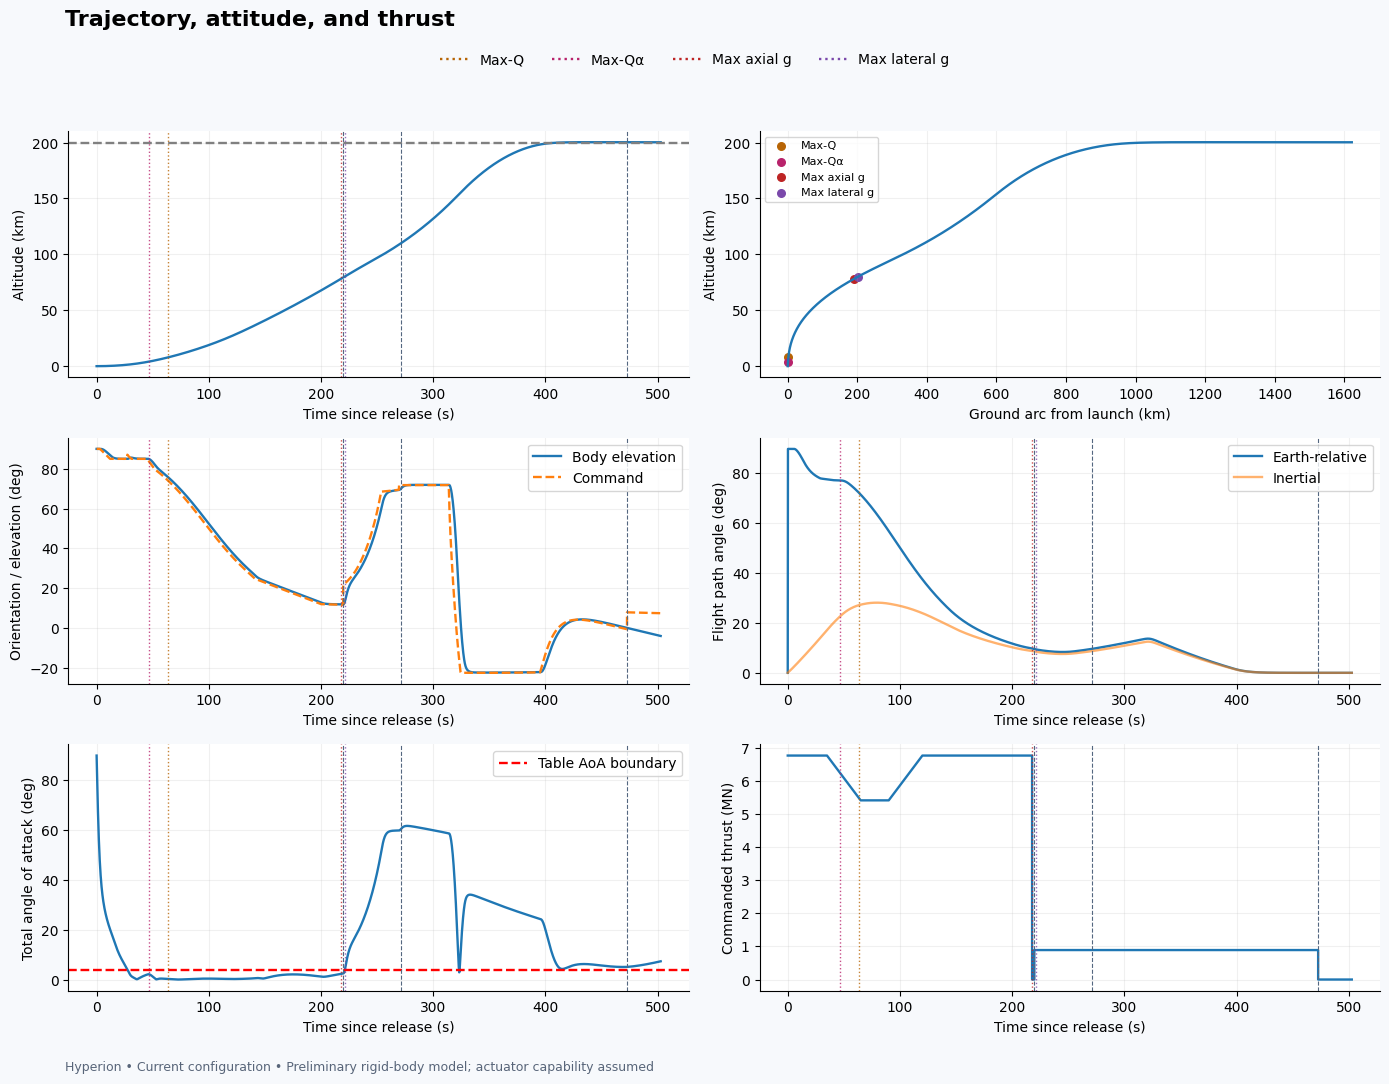

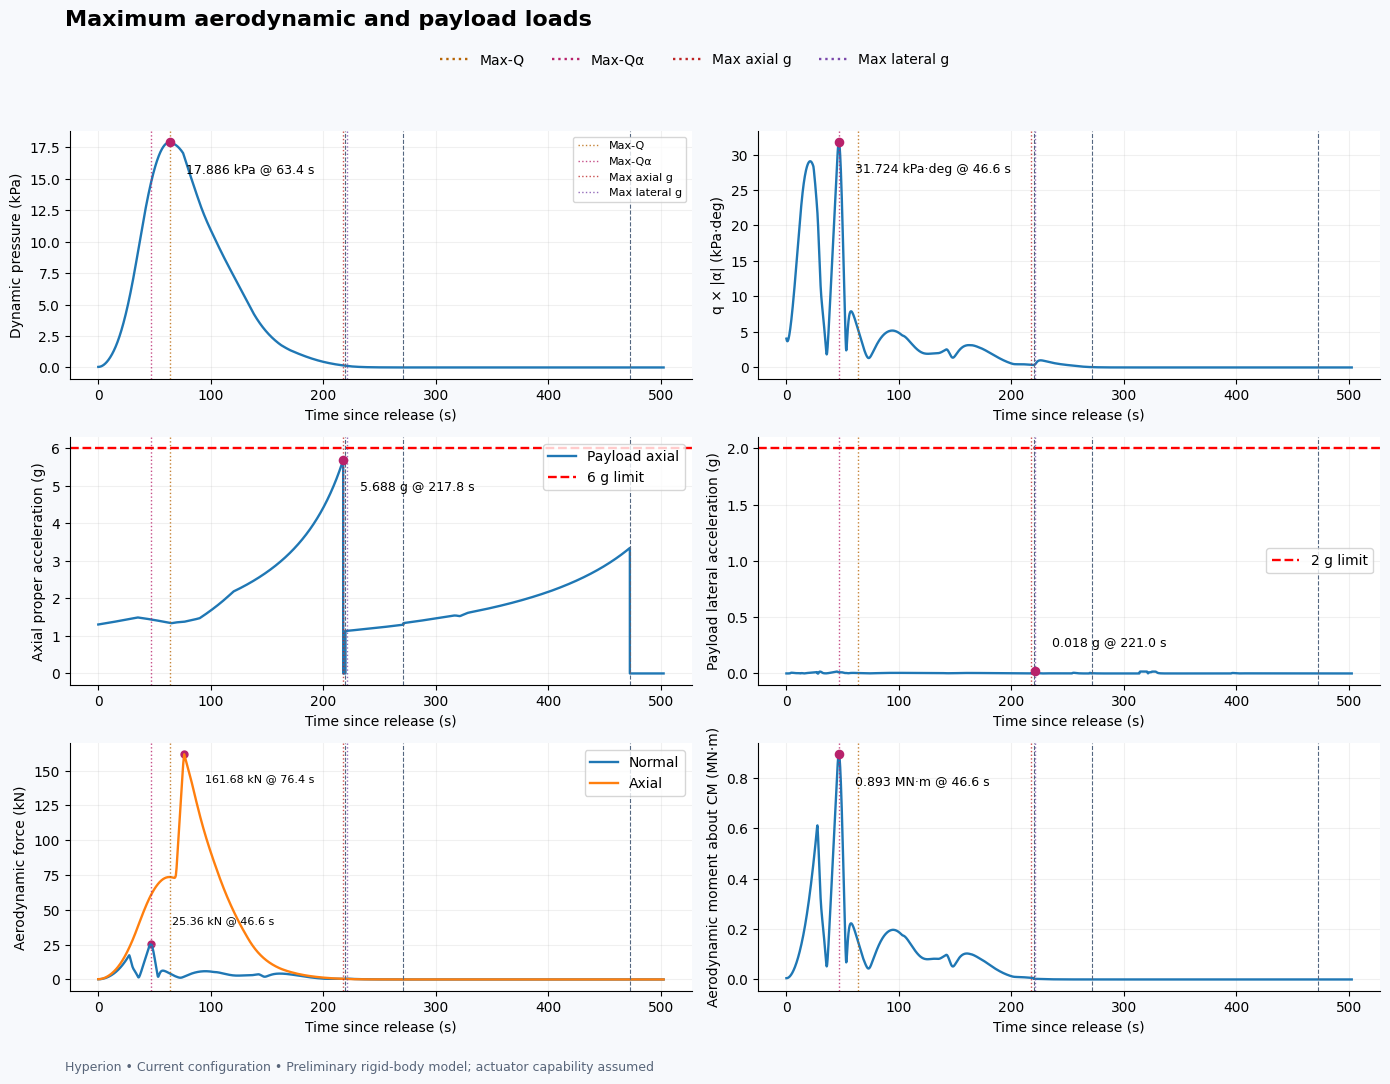

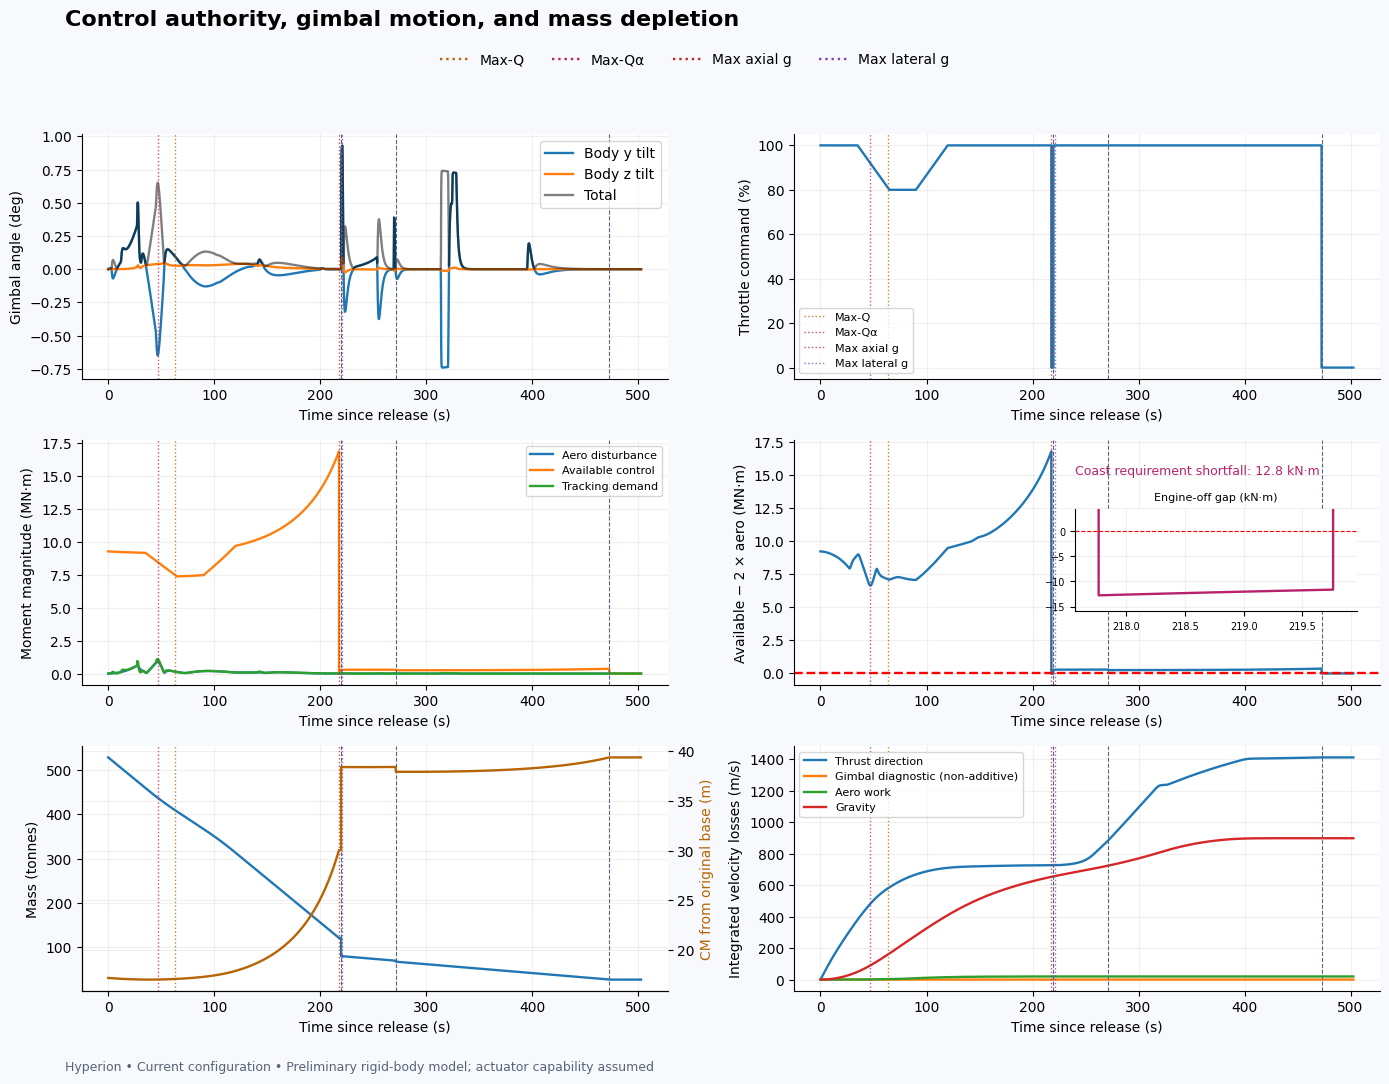

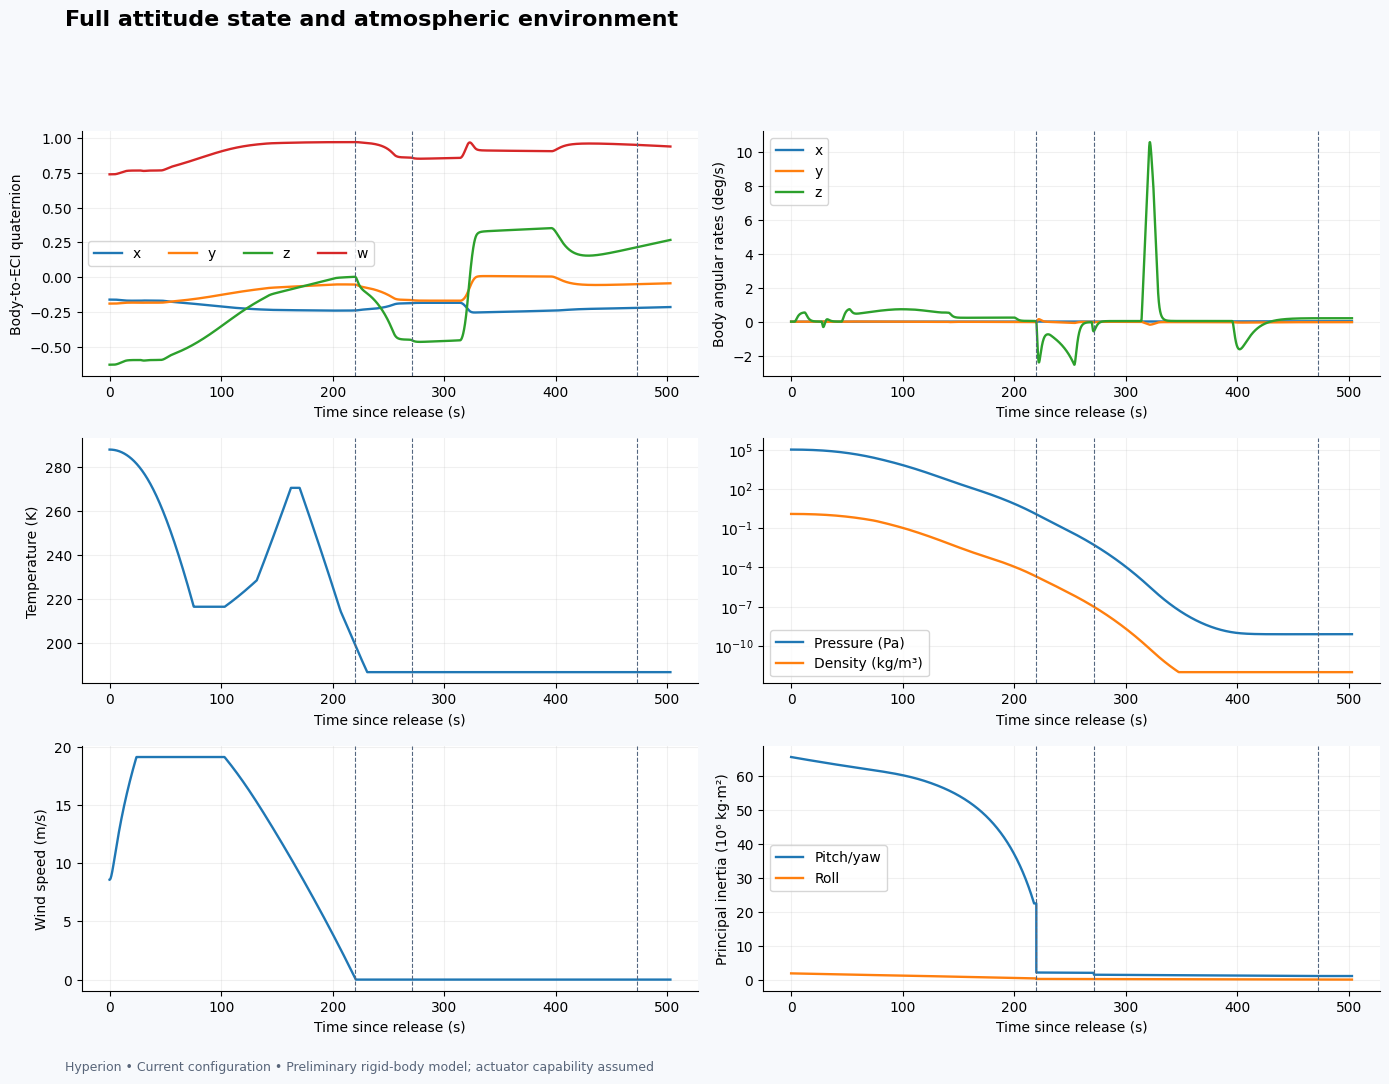

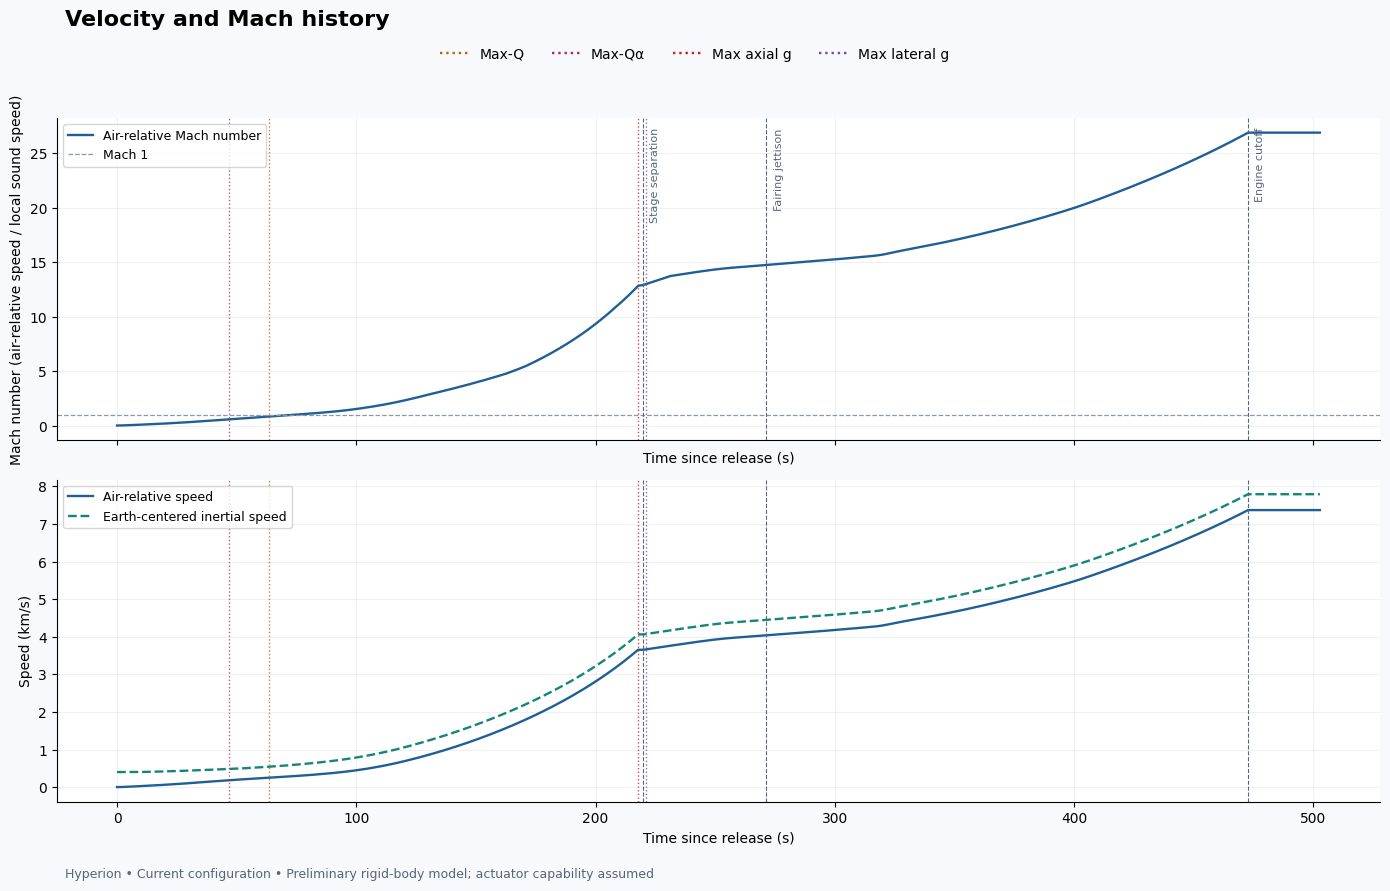

In [17]:
plot_names = ["trajectory", "loads", "control_and_mass", "attitude_and_atmosphere", "velocity_and_mach"]
figures = dict(zip(plot_names, plot_results(flight, summary, simulation.c)))
for figure in figures.values():
    display(figure)
    plt.close(figure)


### Correlated loading cases and events

Each load row is a complete sampled state at one selected extreme. Values in
different rows occur at different times; they must not be combined into an
invented simultaneous load case. These are rigid-body loads for downstream
structural work, not stress, buckling or structural qualification results.


In [18]:
load_columns = {
    "case": "Load case", "t_s": "Time (s)", "altitude_m": "Altitude (m)",
    "mach": "Mach", "alpha_deg": "AoA (deg)", "q_Pa": "Q (Pa)",
    "axial_g": "Axial (g)", "lateral_g": "Lateral (g)",
    "normal_force_N": "Normal force (N)", "aero_moment_Nm": "Aero moment (N·m)",
}
show_table(simulation.load_cases[list(load_columns)].rename(columns=load_columns).round(3))
show_table(pd.DataFrame(summary["events"]))
if departure is not None:
    show_table(pd.DataFrame(departure["events"]))


Load case,Time (s),Altitude (m),Mach,AoA (deg),Q (Pa),Axial (g),Lateral (g),Normal force (N),Aero moment (N·m)
Max-Q,63.400,7787.302,0.834,0.308,17886.384,1.348,0.004,4398.162,154552.784
Max-Qalpha,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011,25361.577,892656.526
Max axial acceleration,217.763,78223.853,12.830,2.273,162.961,5.688,0.001,411.119,6382.989
Max lateral acceleration,220.963,80173.685,12.986,3.435,120.661,1.134,0.018,525.025,2512.076
Max aerodynamic moment,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011,25361.577,892656.526
Max TVC demand,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011,25361.577,892656.526
Max thrust,0.000,18.201,0.025,90.000,45.112,1.305,0.000,144.257,5054.527
Max aerodynamic normal force,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011,25361.577,892656.526
Max aerodynamic axial force,76.400,11291.113,1.051,0.119,16754.353,1.377,0.002,2050.982,70742.613


event,t_s,shed_mass_kg,cg_shift_m,upper_delta_v_m_s,lower_delta_v_m_s
liftoff,0.000000,NaN,NaN,NaN,NaN
MECO,217.762831,NaN,NaN,NaN,NaN
stage_separation,219.762831,40744.129012,8.324391,0.5,-0.987756
stage2_ignition,219.762831,NaN,NaN,NaN,NaN
fairing_jettison,271.358436,2155.278250,NaN,NaN,NaN
orbital_speed_cutoff,472.676346,NaN,NaN,NaN,NaN
end_coast,502.676346,NaN,NaN,NaN,NaN


<a id="departure"></a>
## 5. Coast, restart, and departure

Departure starts from the actual detached, fairing-free upper-stage cutoff
state. The same 6DOF model coasts, subtracts the saved restart inventory and
executes a prograde burn until target energy, residual limit, ground contact
or the burn-time limit. **C3 = V² − 2μ/r**, reported in km²/s²; negative
C3 remains Earth-bound. This energy screen does not solve injection direction
or a Mars encounter. Coast roll/attitude authority remains an open limitation.


In [19]:
def _mission_positive(value, name, allow_zero=False):
    if not math.isfinite(value) or (value < 0 if allow_zero else value <= 0):
        raise ValueError(
            f'{name} must be finite and {"nonnegative" if allow_zero else "positive"}.'
        )
    return float(value)


def _vector(value, name):
    value = np.asarray(value, dtype=float)
    if value.shape != (3,) or not np.isfinite(value).all():
        raise ValueError(f"{name} must contain three finite SI values.")
    return value


def state_from_row(row):
    """Reconstruct all 22 integrated states, including attitude and loss integrals."""
    # Keep the trajectory model's state order: position, velocity, quaternion,
    # body rates, two propellant masses, two gimbal angles, and five integrals.
    names = (
        [f"eci_{k}_m" for k in "xyz"]
        + [f"eci_v{k}_m_s" for k in "xyz"]
        + [f"quaternion_{k}" for k in "xyzw"]
    )
    state = [float(row[k]) for k in names]
    state += list(np.deg2rad([row[f"body_rate_{k}_deg_s"] for k in "xyz"]))
    state += [row["prop1_kg"], row["prop2_kg"]]
    state += list(np.deg2rad([row["gimbal_y_deg"], row["gimbal_z_deg"]]))
    state += [
        row[k]
        for k in [
            "ideal_dv_m_s",
            "steering_loss_m_s",
            "gimbal_loss_m_s",
            "drag_loss_m_s",
            "gravity_loss_m_s",
        ]
    ]
    result = np.asarray(state, dtype=float)
    if not np.isfinite(result).all():
        raise ValueError("Cutoff state contains nonfinite values.")
    return result


class _DepartureSimulation(Simulation):
    def guidance(self, t, r, vrel, v, h, qbar):
        # Prograde steering is an explicit feasible-policy screen, not targeting
        # optimization. The original actuator/6DOF response still follows it.
        return unit(v)


def finite_burn_tmi(
    *,
    cutoff_row,
    config,
    coast_duration_s,
    restart_propellant_kg,
    target_c3_km2_s2,
    max_burn_duration_s,
    output_step_s=1.0,
):
    """Continue an ascent-cutoff state through coast, restart, and finite TMI.

    Required coast/restart values are not silently invented. C3 is the Earth
    two-body characteristic energy, not proof of Mars arrival geometry. Thermal
    boiloff and ignition transients require separate supplied models. The cutoff
    row must describe the detached, fairing-free upper stage; its mass and CG are
    checked against the supplied configuration before any phase transition.
    """
    _mission_positive(coast_duration_s, "coast_duration_s", True)
    _mission_positive(restart_propellant_kg, "restart_propellant_kg", True)
    _mission_positive(max_burn_duration_s, "max_burn_duration_s")
    _mission_positive(output_step_s, "output_step_s")
    if not math.isfinite(target_c3_km2_s2):
        raise ValueError("Target C3 must be finite.")
    run_config = copy.deepcopy(config)
    run_config["solver"]["output_step_s"] = output_step_s
    run_config["solver"]["verbose"] = False
    simulation = _DepartureSimulation(run_config)
    simulation.phase = 3
    simulation.attached = False
    simulation.fairing = False
    simulation.cutoff = True
    state = state_from_row(cutoff_row)
    time = float(cutoff_row["t_s"])
    start_time = time
    if "mass_kg" not in cutoff_row or "cg_from_base_m" not in cutoff_row:
        raise ValueError(
            "Cutoff row must include mass_kg and cg_from_base_m to verify vehicle configuration."
        )
    supplied_mass_cg = np.array(
        [cutoff_row["mass_kg"], cutoff_row["cg_from_base_m"]], dtype=float
    )

    def matches(fairing):
        expected = np.asarray(
            simulation.vehicle.properties(state[13:15], False, fairing)[:2]
        )
        return bool(
            np.all(np.isfinite(supplied_mass_cg))
            and np.allclose(supplied_mass_cg, expected, rtol=1e-8, atol=1e-6)
        )

    if not matches(False):
        if matches(True):
            raise ValueError(
                "Cutoff row retains the fairing; supply an explicit fairing-jettison state before TMI."
            )
        raise ValueError(
            "Cutoff mass/CG is incompatible with the detached, fairing-free upper-stage configuration."
        )
    initial_propellant = float(state[14])
    initial_ideal_delta_v = float(state[17])

    def energy(state):
        """Earth-relative C3 in km²/s²; negative values remain Earth-bound."""
        return (
            np.dot(state[3:6], state[3:6]) - 2 * MU / np.linalg.norm(state[:3])
        ) / 1e6

    def ground(time, state):
        return np.linalg.norm(state[:3]) - RE

    ground.terminal = True
    ground.direction = -1
    simulation.events = [{"event": "ascent_cutoff", "t_s": time}]
    status = "coast_complete"
    if coast_duration_s:
        state, time, solution = simulation.integrate(
            state, time, time + coast_duration_s, [ground]
        )
        if solution.t_events[0].size:
            status = "ground_contact"
    residual_propellant = run_config["vehicle"]["stages"][1]["residual_kg"]
    if status != "ground_contact":
        # An already-satisfied energy target requires no ignition or startup debit.
        if energy(state) >= target_c3_km2_s2:
            status = "C3_already_at_or_above_target"
        elif state[14] - restart_propellant_kg <= residual_propellant:
            status = "insufficient_restart_inventory"
        else:
            cg_before = simulation.vehicle.properties(state[13:15], False, False)[1]
            state[14] -= restart_propellant_kg
            cg_after = simulation.vehicle.properties(state[13:15], False, False)[1]
            cg_shift = matrix(state[6:10]) @ np.array([cg_after - cg_before, 0.0, 0.0])
            state[:3] += cg_shift
            state[3:6] += np.cross(matrix(state[6:10]) @ state[10:13], cg_shift)
            simulation.phase = 2
            simulation.cutoff = False
            simulation.ignition_time = time
            simulation.events.append(
                {
                    "event": "TMI_restart",
                    "t_s": time,
                    "startup_propellant_kg": restart_propellant_kg,
                }
            )

            def depleted(time, state):
                return state[14] - residual_propellant

            depleted.terminal = True
            depleted.direction = -1

            def target(time, state):
                return energy(state) - target_c3_km2_s2

            target.terminal = True
            target.direction = 1
            state, time, solution = simulation.integrate(
                state, time, time + max_burn_duration_s, [depleted, target, ground]
            )
            if solution.t_events[0].size:
                status = "residual_propellant_limit"
            elif solution.t_events[1].size:
                status = "target_C3_reached"
            elif solution.t_events[2].size:
                status = "ground_contact"
            else:
                status = "burn_time_limit"
    simulation.events.append({"event": status, "t_s": time})
    # integrate() retains the powered left-limit at the shutdown event for load
    # checks. Append a separate engine-off right-limit without changing the state.
    simulation.phase = 3
    simulation.cutoff = True
    simulation.rows.append(simulation.evaluate(time, state, True))
    history = pd.DataFrame(simulation.rows)
    final_c3 = float(energy(state))
    powered = history[history.thrust_N > 0]
    maximum_axial_g = float(history.axial_g.abs().max())
    maximum_lateral_g = float(history.lateral_g.abs().max())
    tracking_pass = None
    if not powered.empty:
        tracking_pass = bool(
            (powered.required_moment_Nm <= powered.available_moment_Nm + 1e-6).all()
        )
    return {
        "status": status,
        "target_C3_reached": bool(final_c3 >= target_c3_km2_s2 - 1e-7),
        "target_C3_km2_s2": float(target_c3_km2_s2),
        "achieved_C3_km2_s2": final_c3,
        "C3_margin_km2_s2": final_c3 - target_c3_km2_s2,
        "elapsed_from_ascent_cutoff_s": time - start_time,
        "remaining_propellant_kg": float(state[14]),
        "required_residual_kg": float(residual_propellant),
        "consumed_propellant_kg": initial_propellant - float(state[14]),
        "TMI_ideal_delta_v_m_s": float(state[17] - initial_ideal_delta_v),
        "events": simulation.events,
        "maximum_axial_g": maximum_axial_g,
        "maximum_lateral_g": maximum_lateral_g,
        "axial_acceleration_screen_pass": bool(
            maximum_axial_g <= run_config["limits"]["axial_g"]
        ),
        "lateral_acceleration_screen_pass": bool(
            maximum_lateral_g <= run_config["limits"]["lateral_g"]
        ),
        "powered_tracking_capacity_screen_pass": tracking_pass,
        "history": history.to_dict(orient="records"),
        "assumptions": [
            "Same shared 6DOF dynamics, atmosphere, moving mass, actuator and acceleration limits.",
            "Prograde departure guidance; no optimizer or planetary encounter matching.",
            "Supplied instantaneous restart propellant debit; no ignition shock or boiloff model.",
            "Source gimbal hardware and coast-control limitations remain applicable.",
        ],
    }


def integrated_tmi(
    *,
    coast_duration_s,
    restart_propellant_kg,
    target_c3_km2_s2,
    max_burn_duration_s,
    config=None,
    ascent_history=None,
    output_step_s=1.0,
    context=None,
):
    """Reuse or run the ascent, then continue from its actual orbital-speed cutoff."""
    if context is not None:
        ascent_history, _, simulation = context
        config = simulation.c
    run_config = copy.deepcopy(load_config() if config is None else config)
    if ascent_history is None:
        ascent, summary, simulation = run_trajectory(run_config)
        if not any(e["event"] == "orbital_speed_cutoff" for e in simulation.events):
            return {
                "status": "ascent_did_not_reach_cutoff",
                "target_C3_reached": False,
                "ascent_summary": summary,
            }
    else:
        ascent = pd.DataFrame(ascent_history)
        summary = None
    powered = ascent[(ascent.phase == 2) & (ascent.thrust_N > 0)]
    if powered.empty:
        raise ValueError("Ascent history contains no powered upper-stage state.")
    cutoff_state = powered.iloc[-1].to_dict()
    coast_after_cutoff = ascent[
        (ascent.t_s >= cutoff_state["t_s"]) & (ascent.phase == 3)
    ]
    if coast_after_cutoff.empty:
        raise ValueError(
            "Supplied ascent history does not demonstrate an orbital-cutoff coast."
        )
    result = finite_burn_tmi(
        cutoff_row=cutoff_state,
        config=run_config,
        coast_duration_s=coast_duration_s,
        restart_propellant_kg=restart_propellant_kg,
        target_c3_km2_s2=target_c3_km2_s2,
        max_burn_duration_s=max_burn_duration_s,
        output_step_s=output_step_s,
    )
    if summary is not None:
        result["ascent_summary"] = summary
    return result


In [20]:
if reached_cutoff:
    departure = integrated_tmi(context=context, **departure_inputs)
    departure_history = pd.DataFrame(departure["history"])
    departure_control_margin = departure_history.ratio2_margin_Nm.min()
    departure_results = pd.DataFrame([
        ("Target C3", departure["target_C3_km2_s2"], "km²/s²"),
        ("Achieved C3", departure["achieved_C3_km2_s2"], "km²/s²"),
        ("C3 margin", departure["C3_margin_km2_s2"], "km²/s²"),
        ("Ideal TMI increment", departure["TMI_ideal_delta_v_m_s"], "m/s"),
        ("Remaining propellant", departure["remaining_propellant_kg"], "kg"),
        ("Required residual", departure["required_residual_kg"], "kg"),
        ("Maximum axial acceleration", departure["maximum_axial_g"], "g"),
        ("Maximum lateral acceleration", departure["maximum_lateral_g"], "g"),
        ("Minimum control margin including coast", departure_control_margin / 1000, "kN·m"),
    ], columns=["Result", "Value", "Units"])
    print("Departure ended because:", departure["status"].replace("_", " "))
    show_table(departure_results.round(4))
    show_table(pd.DataFrame(departure["events"]))
else:
    print("Departure unavailable: the ascent did not reach orbital cutoff.")


Departure ended because: residual propellant limit


Result,Value,Units
Target C3,9.8000,km²/s²
Achieved C3,-12.2537,km²/s²
C3 margin,-22.0537,km²/s²
Ideal TMI increment,2837.7318,m/s
Remaining propellant,1917.1458,kg
Required residual,1917.1458,kg
Maximum axial acceleration,5.7999,g
Maximum lateral acceleration,0.0101,g
Minimum control margin including coast,-0.0000,kN·m


event,t_s,startup_propellant_kg
ascent_cutoff,472.676346,NaN
TMI_restart,1072.676346,301.843504
residual_propellant_limit,1136.225949,NaN


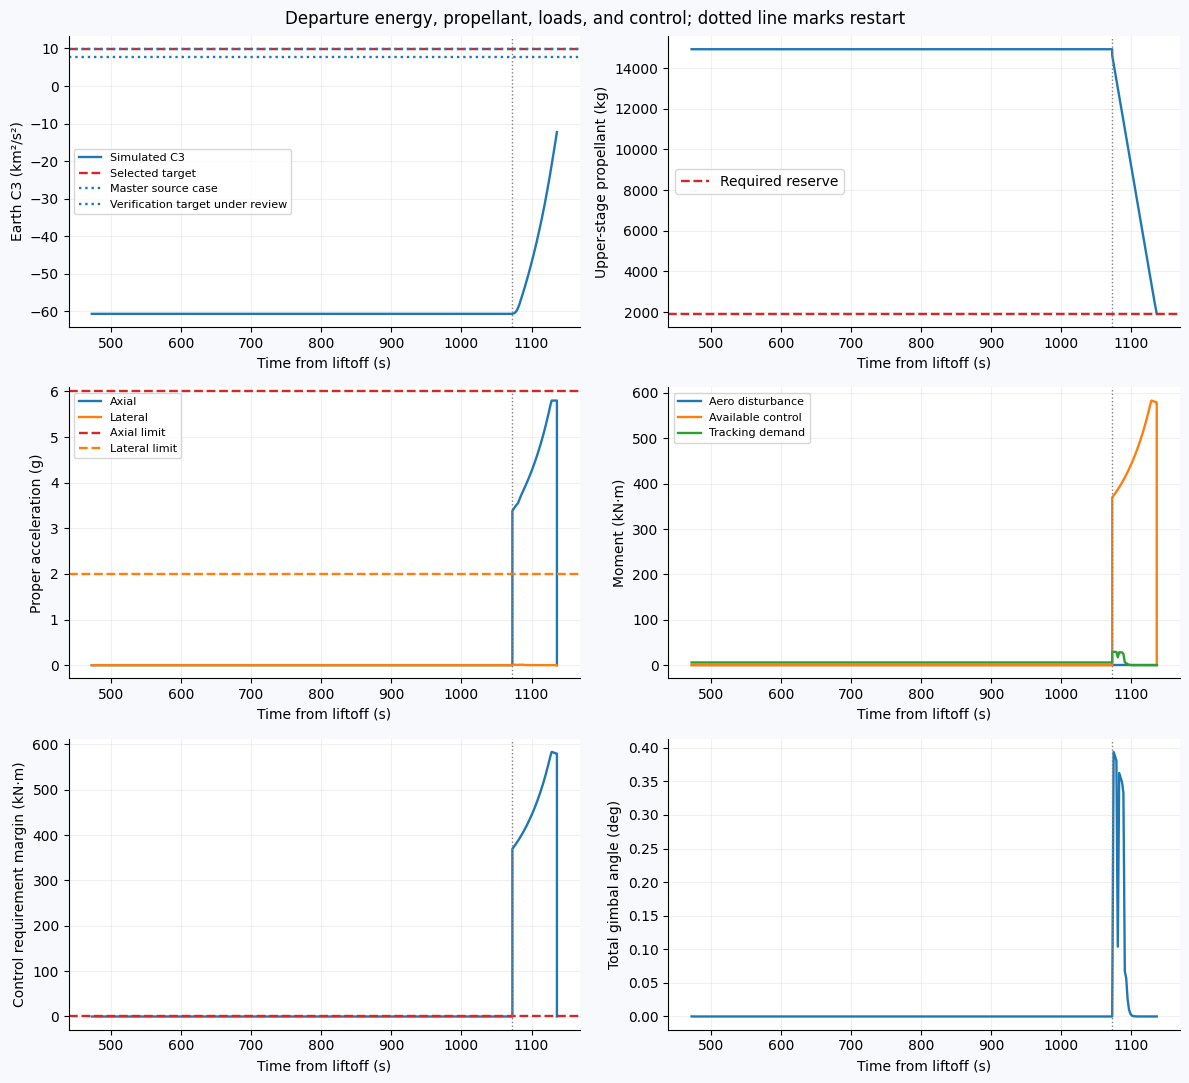

In [21]:
if departure is None:
    print("No departure plot: the ascent did not reach orbital cutoff.")
else:
    position = departure_history[["eci_x_m", "eci_y_m", "eci_z_m"]].to_numpy()
    velocity = departure_history[["eci_vx_m_s", "eci_vy_m_s", "eci_vz_m_s"]].to_numpy()
    c3 = (np.sum(velocity**2, axis=1) - 2 * MU / np.linalg.norm(position, axis=1)) / 1e6
    time = departure_history.t_s

    figure, axes = plt.subplots(3, 2, figsize=(12, 11))
    axes[0, 0].plot(time, c3, label="Simulated C3")
    axes[0, 0].axhline(departure_inputs["target_c3_km2_s2"], color="tab:red", ls="--", label="Selected target")
    for target in departure_targets["targets"]:
        axes[0, 0].axhline(target["target_c3_km2_s2"], ls=":", label=target["label"])
    axes[0, 0].set_ylabel("Earth C3 (km²/s²)")
    axes[0, 0].legend(fontsize=8)
    axes[0, 1].plot(time, departure_history.prop2_kg)
    axes[0, 1].axhline(departure["required_residual_kg"], color="tab:red", ls="--", label="Required reserve")
    axes[0, 1].set_ylabel("Upper-stage propellant (kg)")
    axes[0, 1].legend()

    axes[1, 0].plot(time, departure_history.axial_g, label="Axial")
    axes[1, 0].plot(time, departure_history.lateral_g, label="Lateral")
    axes[1, 0].axhline(config["limits"]["axial_g"], color="tab:red", ls="--", label="Axial limit")
    axes[1, 0].axhline(config["limits"]["lateral_g"], color="tab:orange", ls="--", label="Lateral limit")
    axes[1, 0].set_ylabel("Proper acceleration (g)")
    axes[1, 0].legend(fontsize=8)
    for column, label in [("aero_moment_Nm", "Aero disturbance"), ("available_moment_Nm", "Available control"), ("required_moment_Nm", "Tracking demand")]:
        axes[1, 1].plot(time, departure_history[column] / 1000, label=label)
    axes[1, 1].set_ylabel("Moment (kN·m)")
    axes[1, 1].legend(fontsize=8)

    axes[2, 0].plot(time, departure_history.ratio2_margin_Nm / 1000)
    axes[2, 0].axhline(0, color="tab:red", ls="--")
    axes[2, 0].set_ylabel("Control requirement margin (kN·m)")
    axes[2, 1].plot(time, departure_history.gimbal_total_deg)
    axes[2, 1].set_ylabel("Total gimbal angle (deg)")
    for axis in axes.flat:
        axis.set_xlabel("Time from liftoff (s)")
        for event in departure["events"]:
            if event["event"] == "TMI_restart":
                axis.axvline(event["t_s"], color="grey", ls=":", lw=1)
    figure.suptitle("Departure energy, propellant, loads, and control; dotted line marks restart")
    figure.tight_layout()
    figures["departure"] = figure
    display(figure)
    plt.close(figure)


<a id="engineering"></a>
## 6. Source sizing and installed thrust

Ullage is **1 − liquid mass / (density × tank volume)**. Bottom-up component
totals are compared with dry-mass allocations; the fairing and replacement
adapter bookkeeping is explicit. These calculations check source arithmetic
and reserved volume. They do not predict pressure, thermal conditioning,
ignition, feed-system stability or measured mass.


In [22]:
def _propulsion_positive(value, name, zero=False):
    value = float(value)
    if not math.isfinite(value) or (value < 0 if zero else value <= 0):
        raise ValueError(
            f'{name} must be finite and {"nonnegative" if zero else "positive"}.'
        )
    return value


def thrust_sum(*, per_engine_thrust_N, engine_count):
    """Installed thrust in N for identical engines at the supplied operating point."""
    engine_thrust = _propulsion_positive(per_engine_thrust_N, "per-engine thrust", True)
    if int(engine_count) != engine_count or engine_count < 1:
        raise ValueError("Engine count must be a positive integer.")
    return {
        "installed_thrust_N": engine_thrust * int(engine_count),
        "engine_count": int(engine_count),
    }


def liquid_ullage(*, tank_volume_m3, loaded_liquid_mass_kg, liquid_density_kg_m3):
    volume = _propulsion_positive(tank_volume_m3, "tank volume")
    mass = _propulsion_positive(loaded_liquid_mass_kg, "loaded liquid mass", True)
    liquid = mass / _propulsion_positive(liquid_density_kg_m3, "liquid density")
    ullage = volume - liquid
    return {
        "liquid_volume_m3": liquid,
        "ullage_volume_m3": ullage,
        "ullage_fraction": ullage / volume,
        "geometric_fill_pass": bool(ullage >= 0),
    }


def sourced_sizing(context, tanks, component_mass_kg, allocated_mass_kg):
    """Recompute tank volumes/ullage and bottom-up dry mass against allocations.

    Each tank supplies name, volume_m3, loaded_mass_kg, density_kg_m3. Component
    totals must include fairing/adapter bookkeeping explicitly; do not compare an
    allocation to itself. Tank density and geometry are source design values.
    """

    rows = []
    for tank in tanks:
        # Validate the source values with the shared tank calculation.
        liquid_ullage(
            tank_volume_m3=tank["volume_m3"],
            loaded_liquid_mass_kg=tank["loaded_mass_kg"],
            liquid_density_kg_m3=tank["density_kg_m3"],
        )
        liquid = tank["loaded_mass_kg"] / tank["density_kg_m3"]
        rows.append(
            {
                "tank": tank["name"],
                "liquid_volume_m3": liquid,
                "tank_volume_m3": tank["volume_m3"],
                "ullage_fraction": 1 - liquid / tank["volume_m3"],
            }
        )
    components = np.asarray(component_mass_kg, dtype=float)
    allocations = np.asarray(allocated_mass_kg, dtype=float)
    if (
        components.shape != allocations.shape
        or not len(components)
        or not np.isfinite(components).all()
        or not np.isfinite(allocations).all()
        or np.any(components < 0)
        or np.any(allocations <= 0)
    ):
        raise ValueError(
            "Matching nonnegative component totals and positive allocations required."
        )
    return {
        "tanks": rows,
        "minimum_ullage_fraction": min(r["ullage_fraction"] for r in rows),
        "dry_mass_margin_kg": (allocations - components).tolist(),
        "minimum_dry_mass_margin_kg": float((allocations - components).min()),
        "basis": "Source bottom-up totals; fairing and replacement adapter hardware included explicitly. Not a measured mass record.",
    }


In [23]:
def _plain(value):
    """Convert NumPy results to JSON values; nonfinite numbers become null."""
    if isinstance(value, dict):
        return {str(key): _plain(item) for key, item in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [_plain(item) for item in value]
    if isinstance(value, (np.integer, np.floating, np.bool_)):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


def acceptance(metrics, rules):
    """Apply explicit scalar rules with units and a source; no inferred thresholds."""
    outcomes = []
    for rule in rules:
        if not rule.get("source") or not rule.get("units"):
            raise ValueError("Every acceptance rule needs units and a source.")
        value = metrics
        for key in rule["metric"].split("."):
            value = value[key]
        if value is None or not np.isscalar(value) or not np.isfinite(value):
            raise ValueError(f"No finite scalar for {rule['metric']}")
        operators = {
            "<=": lambda value, limit: value <= limit,
            ">=": lambda value, limit: value >= limit,
            "<": lambda value, limit: value < limit,
            ">": lambda value, limit: value > limit,
            "==": lambda value, limit: value == limit,
        }
        outcomes.append(bool(operators[rule["operator"]](value, rule["limit"])))
    return all(outcomes) if outcomes else None


In [24]:
sizing_inputs = checks["sourced_sizing"]["inputs"]
ullage_rules = checks["PROP.3.TANK.02.A01"].get("acceptance", [])
sizing = sourced_sizing(context=context, **sizing_inputs)
verdict = {True: "Meets saved criteria", False: "Needs attention", None: "No acceptance rule supplied"}
show_table(pd.DataFrame(sizing_inputs["tanks"]).round(3))
print("Sizing basis:", checks["sourced_sizing"]["basis"])
show_table(pd.DataFrame(ullage_rules))


name,volume_m3,loaded_mass_kg,density_kg_m3
Stage1 methane,217.891,91892.297,451.256
Stage1 LOX,271.650,330812.269,1237.800
Stage2 hydrogen,132.371,9446.264,75.130
Stage2 LOX,48.275,56677.585,1237.800


Sizing basis: Current Mlox-Hlox Vehicle Sizing G4:H5,F19:G20,B31:C32; Vehicle Mass E29/E44 totals plus fairing2155.27825kg and adapter replacement845−431.976225kg. Bottom-up totals retained to source precision.


metric,operator,limit,units,source
minimum_ullage_fraction,>=,0.04,fraction,PROP.3.TANK.02 [TBR-PROP-36]


Tank,Liquid volume (m³),Tank volume (m³),Ullage (%)
Stage1 methane,203.637,217.891,6.542
Stage1 LOX,267.258,271.650,1.617
Stage2 hydrogen,125.732,132.371,5.015
Stage2 LOX,45.789,48.275,5.150


Tank-sizing screen: Needs attention


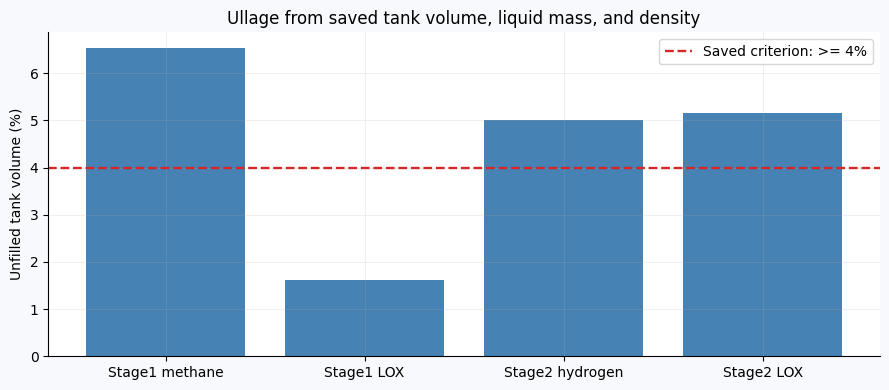

Stage,Component rollup (kg),Allocation (kg),Margin (kg)
Stage 1,22660.755,30673.733,8012.979
Stage 2,7783.826,7898.353,114.527


In [25]:
tanks = pd.DataFrame(sizing["tanks"])
tanks["Ullage (%)"] = tanks.pop("ullage_fraction") * 100
tanks = tanks.rename(columns={
    "tank": "Tank", "liquid_volume_m3": "Liquid volume (m³)", "tank_volume_m3": "Tank volume (m³)",
})
show_table(tanks.round(3))
print("Tank-sizing screen:", verdict[acceptance(sizing, ullage_rules)])

figure, axis = plt.subplots(figsize=(9, 4))
axis.bar(tanks["Tank"], tanks["Ullage (%)"], color="steelblue")
for rule in ullage_rules:
    if rule["metric"] == "minimum_ullage_fraction":
        limit_percent = rule["limit"] * 100
        axis.axhline(limit_percent, color="tab:red", ls="--",
                     label=f"Saved criterion: {rule['operator']} {limit_percent:g}%")
axis.set(ylabel="Unfilled tank volume (%)", title="Ullage from saved tank volume, liquid mass, and density")
if axis.get_legend_handles_labels()[0]:
    axis.legend()
figure.tight_layout()
figures["tank_ullage"] = figure
display(figure)
plt.close(figure)

mass_allocation = pd.DataFrame({
    "Stage": [stage["name"] for stage in config["vehicle"]["stages"]],
    "Component rollup (kg)": sizing_inputs["component_mass_kg"],
    "Allocation (kg)": sizing_inputs["allocated_mass_kg"],
    "Margin (kg)": sizing["dry_mass_margin_kg"],
})
show_table(mass_allocation.round(3))


### Supplied Earth–Mars cases

The two-body Lambert calculation compares three supplied ephemeris pairs at
fixed time of flight. Positions and velocities retain their source frame,
units and provenance. These samples are not a launch-window sweep or global
optimum, and do not establish launch-site access or full-mission margins.


In [26]:
def _stumpff(z):
    if abs(z) < 1e-6:
        return (
            0.5 - z / 24 + z * z / 720 - z**3 / 40320,
            1 / 6 - z / 120 + z * z / 5040 - z**3 / 362880,
        )
    x = math.sqrt(abs(z))
    if z > 0:
        return (1 - math.cos(x)) / z, (x - math.sin(x)) / x**3
    return (math.cosh(x) - 1) / (-z), (math.sinh(x) - x) / x**3


def lambert(
    *,
    departure_position_m,
    arrival_position_m,
    time_of_flight_s,
    central_mu_m3_s2,
    long_way=False,
):
    """Zero-revolution universal-variable solution; endpoints share one inertial frame.

    `long_way` chooses transfer angle > pi. Collinear endpoints are rejected;
    they require a specified transfer plane and a different singularity treatment.
    """
    departure_position = _vector(departure_position_m, "departure_position_m")
    arrival_position = _vector(arrival_position_m, "arrival_position_m")
    mu = _mission_positive(central_mu_m3_s2, "central_mu_m3_s2")
    flight_time = _mission_positive(time_of_flight_s, "time_of_flight_s")
    departure_radius = np.linalg.norm(departure_position)
    arrival_radius = np.linalg.norm(arrival_position)
    _mission_positive(departure_radius, "departure radius")
    _mission_positive(arrival_radius, "arrival radius")
    cos_angle = float(
        np.clip(
            np.dot(departure_position, arrival_position)
            / (departure_radius * arrival_radius),
            -1,
            1,
        )
    )
    sin_angle = math.sqrt(max(0.0, 1 - cos_angle * cos_angle)) * (-1 if long_way else 1)
    if abs(sin_angle) < 1e-9:
        raise ValueError(
            "Collinear Lambert endpoints require a specified transfer plane."
        )
    transfer_geometry = sin_angle * math.sqrt(
        departure_radius * arrival_radius / (1 - cos_angle)
    )

    def geometry(z):
        stumpff_c, stumpff_s = _stumpff(z)
        if stumpff_c <= 0:
            return None
        y = (
            departure_radius
            + arrival_radius
            + transfer_geometry * (z * stumpff_s - 1) / math.sqrt(stumpff_c)
        )
        if y < 0:
            return None
        elapsed = (
            (y / stumpff_c) ** 1.5 * stumpff_s + transfer_geometry * math.sqrt(y)
        ) / math.sqrt(mu)
        return elapsed, y

    # The zero-revolution branch ends at the first positive Stumpff singularity.
    grid = np.r_[
        -np.geomspace(1e4, 1e-8, 700),
        0.0,
        np.linspace(1e-8, 4 * math.pi**2 - 1e-6, 700),
    ]
    previous = None
    bracket = None
    for z in grid:
        value = geometry(float(z))
        if value is None:
            continue
        f = value[0] - flight_time
        if previous is not None and previous[1] * f <= 0:
            bracket = (previous[0], float(z))
            break
        previous = (float(z), f)
    if bracket is None:
        raise ValueError(
            "No zero-revolution Lambert root bracketed for these endpoints/time."
        )
    z = brentq(lambda z: geometry(z)[0] - flight_time, *bracket, xtol=1e-12, rtol=1e-13)
    elapsed, y = geometry(z)
    f = 1 - y / departure_radius
    g = transfer_geometry * math.sqrt(y / mu)
    gdot = 1 - y / arrival_radius
    departure_velocity = (arrival_position - f * departure_position) / g
    arrival_velocity = (gdot * arrival_position - departure_position) / g
    return {
        "departure_velocity_m_s": departure_velocity.tolist(),
        "arrival_velocity_m_s": arrival_velocity.tolist(),
        "time_of_flight_residual_s": float(elapsed - flight_time),
        "universal_parameter": float(z),
        "branch": (
            "zero-revolution long-way" if long_way else "zero-revolution short-way"
        ),
    }


def lambert_window(*, cases, central_mu_m3_s2):
    """Evaluate supplied ephemeris/date pairs; no fabricated planet ephemerides.

    Each case includes endpoint positions, planet velocities, flight time, and
    optional date labels. The caller must supply a common inertial frame/epoch.
    Declination is relative to the supplied XY plane; use equatorial ICRF states.
    """
    output = []
    if not cases:
        raise ValueError("At least one ephemeris case is required.")
    for case in cases:
        result = lambert(
            departure_position_m=case["departure_position_m"],
            arrival_position_m=case["arrival_position_m"],
            time_of_flight_s=case["time_of_flight_s"],
            central_mu_m3_s2=central_mu_m3_s2,
            long_way=case.get("long_way", False),
        )
        departure_excess = np.asarray(result["departure_velocity_m_s"]) - _vector(
            case["departure_planet_velocity_m_s"], "departure_planet_velocity_m_s"
        )
        arrival_excess = np.asarray(result["arrival_velocity_m_s"]) - _vector(
            case["arrival_planet_velocity_m_s"], "arrival_planet_velocity_m_s"
        )
        result.update(
            {
                "departure_label": case.get("departure_label", "supplied epoch"),
                "arrival_label": case.get("arrival_label", "supplied epoch"),
                "departure_C3_km2_s2": float(
                    np.dot(departure_excess, departure_excess) / 1e6
                ),
                "departure_excess_velocity_m_s": departure_excess.tolist(),
                "departure_declination_deg": float(
                    np.degrees(
                        np.arctan2(
                            departure_excess[2], np.linalg.norm(departure_excess[:2])
                        )
                    )
                ),
                "arrival_excess_speed_m_s": float(np.linalg.norm(arrival_excess)),
            }
        )
        output.append(result)
    return {
        "cases": output,
        "minimum_C3_case_index": int(
            np.argmin([x["departure_C3_km2_s2"] for x in output])
        ),
        "scope": "Minimum among supplied samples only; not a global launch-window optimization.",
    }


In [27]:
mission_cases = load_mission_cases()
mission_inputs = checks["lambert_window"]["inputs"]
print("Mission scope:", mission_cases["scope"])
show_table(pd.DataFrame(mission_inputs["cases"])[
    ["departure_label", "arrival_label", "time_of_flight_s", "long_way"]])
window = lambert_window(**mission_inputs)


window_columns = {
    "departure_label": "Departure date", "departure_C3_km2_s2": "C3 (km²/s²)",
    "departure_declination_deg": "Declination (deg)",
    "arrival_excess_speed_m_s": "Arrival excess speed (m/s)",
}
window_results = pd.DataFrame(window["cases"])[list(window_columns)].rename(columns=window_columns)
show_table(window_results.round(4))


Mission scope: Three daily departure samples at fixed 274 day TOF, not a comprehensive launch-window optimization.


departure_label,arrival_label,time_of_flight_s,long_way
2033-04-27 00:00 TDB,2034-01-26 00:00 TDB,23673600.0,True
2033-04-28 00:00 TDB,2034-01-27 00:00 TDB,23673600.0,True
2033-04-29 00:00 TDB,2034-01-28 00:00 TDB,23673600.0,True


Departure date,C3 (km²/s²),Declination (deg),Arrival excess speed (m/s)
2033-04-27 00:00 TDB,7.7237,-10.3665,4375.8107
2033-04-28 00:00 TDB,7.7090,-11.3763,4376.2099
2033-04-29 00:00 TDB,7.7055,-12.4805,4376.2699


<a id="verification"></a>
## 7. Assigned verification activities

Exact activity IDs and wording select five explicit calculations. Shared
calculations run once for identical inputs; acceptance is evaluated separately
for every activity. Reviewed records require the current code/input identity,
matching activity text, file hash and reviewer. Numerical screens cannot close
parent requirements with other activities or unresolved TBD/TBR values.

The following definitions keep those rules beside their results. Adding an
acceptance rule does not add an assignment; edit `[[assignments]]` in
verification.toml when the authorized scope changes.


In [28]:
def calculation_key(name, inputs):
    """Reuse a result only for the same named calculation and exact inputs."""
    return json.dumps([name, inputs], sort_keys=True)

def load_requirements():
    """Read the imported requirements, including their source references."""
    return load_reference()["requirements"]


def catalog():
    """Return the five assigned calculations, without scanning module registries.

    The empty second item preserves the historical tuple interface. Activity
    routing comes exclusively from inputs/verification.toml.
    """

    return {
        "flight_summary": flight_summary,
        "integrated_tmi": integrated_tmi,
        "lambert_window": lambert_window,
        "sourced_sizing": sourced_sizing,
        "thrust_sum": thrust_sum,
    }, {}


def load_scope(scope_file=None):
    """Read the explicit assignment list; source prose never selects a route."""
    path = Path(scope_file) if scope_file is not None else ROOT / "inputs/verification.toml"
    with path.open("rb") as stream:
        scope = tomllib.load(stream)
    if not isinstance(scope.get("description"), str) or not scope["description"].strip():
        raise ValueError("Verification scope needs a nonempty description.")
    entries = scope.get("assignments", scope.get("activities"))
    scope["activities"] = entries
    if not isinstance(entries, list) or not entries:
        raise ValueError("Verification scope needs at least one [[assignments]] entry.")
    seen = set()
    for entry in entries:
        if not isinstance(entry, dict):
            raise ValueError("Each verification scope entry must be a table.")
        for key in ("activity_id", "calculation", "expected_activity", "artifact", "coverage"):
            if not isinstance(entry.get(key), str) or not entry[key].strip():
                raise ValueError(f"Verification scope entry needs nonempty {key}.")
        identifier = entry["activity_id"]
        if identifier in seen:
            raise ValueError(f"Duplicate scoped activity ID: {identifier}")
        seen.add(identifier)
        if entry["calculation"] not in CALCULATIONS:
            raise ValueError(
                f"Unknown calculation route {entry['calculation']!r} for {identifier}."
            )
    return scope


def validate_scope(requirements, scope_file=None):
    """Resolve exact activity IDs and reject source wording that has changed.

    This also validates a full workbook before the importer writes its selected
    requirements. Unassigned workbook activities are retained as closure context
    inside those requirement records, but are never added to the run.
    """
    scope = load_scope(scope_file)
    source = {}
    seen_requirements = set()
    for requirement in requirements:
        identifier = requirement["id"]
        if identifier in seen_requirements:
            raise ValueError(f"Duplicate source requirement ID: {identifier}")
        seen_requirements.add(identifier)
        for number, activity in enumerate(requirement["activities"], 1):
            source[f"{identifier}.A{number:02d}"] = requirement, activity
    rows = []
    for entry in scope["activities"]:
        identifier = entry["activity_id"]
        if identifier not in source:
            raise ValueError(f"Unknown scoped activity ID: {identifier}")
        requirement, activity = source[identifier]
        if entry["expected_activity"] != activity:
            raise ValueError(
                f"Scoped activity wording mismatch for {identifier}: "
                f"expected {entry['expected_activity']!r}; source is {activity!r}. "
                "Review the assignment against the current workbook."
            )
        rows.append({
            "activity_id": identifier,
            "requirement_id": requirement["id"],
            "domain": requirement["domain"],
            "activity": activity,
            "kernel": entry["calculation"],
            "artifact": entry["artifact"],
            "coverage": entry["coverage"],
            "methods": " / ".join(requirement["methods"]),
            "source": requirement["source_ref"],
            "statement": requirement["statement"],
            "open_parameters": ", ".join(requirement["open_parameters"]),
            "source_file": requirement.get("source_file", ""),
            "source_sha256": requirement.get("source_sha256", ""),
        })
    return rows


def activities(scope_file=None):
    """Return only assigned rows, with exact current source wording and coverage."""
    return pd.DataFrame(validate_scope(load_requirements(), scope_file))


def input_contracts(scope_file=None):
    """List required arguments for the calculations selected in the scope."""
    functions, _ = catalog()
    rows = []
    for key in dict.fromkeys(activities(scope_file).kernel):
        function = functions[key]
        required_inputs = []
        for name, parameter in inspect.signature(function).parameters.items():
            has_default = parameter.default is not inspect.Parameter.empty
            accepts_many = parameter.kind in (
                inspect.Parameter.VAR_POSITIONAL,
                inspect.Parameter.VAR_KEYWORD,
            )
            if not has_default and not accepts_many:
                required_inputs.append(name)
        rows.append(
            {
                "calculation": key,
                "required_inputs": ", ".join(required_inputs),
                "description": (inspect.getdoc(function) or "").split("\n")[0],
            }
        )
    return pd.DataFrame(rows)


def activity_index(scope_file=None):
    """Link each assigned activity to its explicit calculation route."""
    table = activities(scope_file)
    functions, _ = catalog()
    code_routes = []
    route_types = []
    for kernel in table.kernel:
        if isinstance(kernel, str):
            function = functions[kernel]
            code_routes.append(f"Hyperion.ipynb · {function.__name__}()")
            route_types.append("calculation")
        else:
            code_routes.append("Hyperion.ipynb · check_evidence() / measured_limits()")
            route_types.append("external evidence validation")
    table["code_route"] = code_routes
    table["route_type"] = route_types
    return table


def check_evidence(record, root=ROOT, expected_configuration=None):
    """Validate a reviewed external record and its file hash, not its engineering truth.

    Required fields: file, sha256, reviewer, date, result, configuration_id,
    acceptance_criteria, scope. The reviewer must explicitly cover this activity.
    Paths must stay within the repository; a missing record stays open.
    """
    required_fields = (
        "file",
        "sha256",
        "reviewer",
        "date",
        "result",
        "configuration_id",
        "acceptance_criteria",
        "scope",
    )
    missing = [key for key in required_fields if not record.get(key)]
    if missing:
        return "EVIDENCE_REQUIRED", "Missing record fields: " + ", ".join(missing)
    if expected_configuration is not None:
        if record["configuration_id"] != expected_configuration:
            return (
                "STALE_EVIDENCE",
                "Reviewed configuration differs from the current model/data/requirements baseline.",
            )
    root = Path(root).resolve()
    path = (root / record["file"]).resolve()
    if not path.is_relative_to(root):
        return "INVALID_EVIDENCE", "Evidence file must remain within the repository."
    if not path.is_file():
        return "EVIDENCE_REQUIRED", f"Missing evidence file: {record['file']}"
    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    if actual_hash != record["sha256"]:
        return "INVALID_EVIDENCE", "File hash differs from the reviewed evidence."
    if record["result"] not in ("pass", "fail"):
        return "INVALID_EVIDENCE", "Reviewed result must be pass or fail."
    status = "REVIEWED_PASS" if record["result"] == "pass" else "REVIEWED_FAIL"
    return status, record["scope"]


def measured_limits(csv_path):
    """Evaluate a supplied measurement/result CSV against explicit row limits.

    Columns: case_id, quantity, value, unit, lower_limit, upper_limit, criterion_source.
    At least one finite bound is required per row. Missing/non-numeric values and
    duplicate case/quantity rows are invalid, never successful zero measurements.
    The responsible reviewer establishes required test-case coverage separately.
    """
    frame = pd.read_csv(csv_path)
    required = [
        "case_id",
        "quantity",
        "value",
        "unit",
        "lower_limit",
        "upper_limit",
        "criterion_source",
    ]
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError(
            "A nonempty measurement table with all required columns is needed."
        )
    if frame.duplicated(["case_id", "quantity"]).any():
        raise ValueError(
            "Duplicate case/quantity measurements require explicit distinct case IDs."
        )
    for key in ["case_id", "quantity", "unit", "criterion_source"]:
        if frame[key].isna().any() or frame[key].astype(str).str.strip().eq("").any():
            raise ValueError(f"Missing measurement metadata: {key}")
    for key in ["value", "lower_limit", "upper_limit"]:
        frame[key] = pd.to_numeric(frame[key], errors="raise")
    missing_limits = frame[["lower_limit", "upper_limit"]].isna().all(axis=1)
    if not np.isfinite(frame.value).all() or missing_limits.any():
        raise ValueError(
            "Every measurement requires a finite value and at least one limit."
        )
    for key in ["lower_limit", "upper_limit"]:
        if np.isinf(frame[key].dropna()).any():
            raise ValueError("Bounds must be finite when supplied.")
    if (frame.lower_limit > frame.upper_limit).any():
        raise ValueError("Lower bound exceeds upper bound.")
    above_lower_limit = frame.lower_limit.isna() | (frame.value >= frame.lower_limit)
    below_upper_limit = frame.upper_limit.isna() | (frame.value <= frame.upper_limit)
    frame["within_limits"] = above_lower_limit & below_upper_limit
    return frame


def evaluate(input_file=None, evidence_file=None, context=None, scope_file=None, calculated=None):
    """Run only assigned activities, retaining acceptance and evidence checks.

    Inputs are keyed by activity ID (specific) or calculation name (shared).
    A shared result is cached only for the identical kernel/arguments/criteria.
    Context carries the one integrated flight run; never read stale result CSVs.
    """
    selected = activities(scope_file)
    functions, _ = catalog()
    inputs = load_checks(input_file)
    evidence = load_reference().get("reviewed_evidence", {})
    if evidence_file is not None:
        evidence = _read_json(evidence_file) if Path(evidence_file).exists() else {}

    rows = []
    details = {}
    cache = dict(calculated or {})
    current_baseline = baseline_id()
    for activity in selected.to_dict("records"):
        activity_id = activity["activity_id"]
        kernel = activity["kernel"]
        record = evidence.get(activity_id)
        if record:
            status, note = check_evidence(
                record, expected_configuration=current_baseline
            )
            # A record cannot close a different activity or unknown configuration.
            if record.get("activity_id") != activity_id:
                status, note = (
                    "INVALID_EVIDENCE",
                    "Activity ID does not match the reviewed record.",
                )
            if record.get("activity_text") != activity["activity"]:
                status, note = (
                    "STALE_EVIDENCE",
                    "Reviewed activity wording differs from the current requirement activity.",
                )
            rows.append({**activity, "status": status, "detail": note})
            continue
        if not isinstance(kernel, str) or not kernel:
            rows.append(
                {
                    **activity,
                    "status": "EVIDENCE_REQUIRED",
                    "detail": "Add the CAD/FEA, specialist analysis, inspection, demonstration or test record for this activity; see the reviewed-evidence notes in this notebook.",
                }
            )
            continue

        # Activity-specific inputs override inputs shared by a calculation.
        spec = inputs.get(activity_id, inputs.get(kernel, {}))
        kwargs = dict(spec.get("inputs", {}))
        function = functions[kernel]
        signature = inspect.signature(function)
        if "context" in signature.parameters:
            kwargs["context"] = context

        missing = []
        for name, parameter in signature.parameters.items():
            has_default = parameter.default is not inspect.Parameter.empty
            accepts_many = parameter.kind in (
                inspect.Parameter.VAR_KEYWORD,
                inspect.Parameter.VAR_POSITIONAL,
            )
            if not has_default and not accepts_many and kwargs.get(name) is None:
                missing.append(name)
        if missing:
            rows.append(
                {**activity, "status": "MISSING_INPUTS", "detail": ", ".join(missing)}
            )
            continue

        cache_key = calculation_key(kernel, spec.get("inputs", {}))
        try:
            if cache_key not in cache:
                cache[cache_key] = _plain(function(**kwargs))
            result = cache[cache_key]
            passed = acceptance(result, spec.get("acceptance", []))
            details[activity_id] = result
            if passed is None:
                status = "CALCULATED"
            elif passed:
                status = "SCREEN_PASS"
            else:
                status = "SCREEN_FAIL"
            note = spec.get(
                "basis",
                "Calculation only; activity-specific acceptance and model validation remain required.",
            )
            if spec.get("example_only", False):
                status, note = (
                    "EXAMPLE_ONLY",
                    "Illustrative inputs; this is not Hyperion verification evidence.",
                )
        except (
            ValueError,
            KeyError,
            TypeError,
            RuntimeError,
            np.linalg.LinAlgError,
        ) as error:
            status, note = "INVALID_INPUTS", str(error)
        rows.append({**activity, "status": status, "detail": note})
    return pd.DataFrame(rows), details


def requirement_status(results, scope_file=None):
    """Summarize assigned coverage separately from whole-requirement closure.

    Only requirements represented by assigned results appear. Even reviewed
    assigned work cannot close a requirement with other source activities.
    """
    selected = activities(scope_file)
    results = results[results.activity_id.isin(selected.activity_id)]
    requirements = {row["id"]: row for row in load_requirements()}
    rows = []
    for identifier in results.requirement_id.drop_duplicates():
        if identifier not in requirements:
            raise ValueError(f"Unknown result requirement ID: {identifier}")
        requirement = requirements[identifier]
        group = results[results.requirement_id == identifier]
        assigned = set(selected.loc[selected.requirement_id == identifier, "activity_id"])
        complete_assigned = (
            set(group.activity_id) == assigned
            and len(group) == len(assigned)
            and bool(assigned)
        )
        failed = group.status.isin(
            [
                "SCREEN_FAIL",
                "REVIEWED_FAIL",
                "INVALID_EVIDENCE",
                "INVALID_INPUTS",
            ]
        ).any()
        expected = {
            f"{requirement['id']}.A{number:02d}"
            for number in range(1, len(requirement["activities"]) + 1)
        }
        # Matching IDs alone would overlook duplicate records.
        complete = (
            set(group.activity_id) == expected
            and len(group) == len(expected)
            and bool(expected)
        )
        reviewed = complete and group.status.eq("REVIEWED_PASS").all()
        status = "FAILED_OR_INVALID" if failed else "OPEN"
        if reviewed and not requirement["open_parameters"]:
            status = "REVIEWED_COMPLETE"
        calculated = group.status.isin(["CALCULATED", "SCREEN_PASS", "SCREEN_FAIL"])
        rows.append(
            {
                "id": requirement["id"],
                "domain": requirement["domain"],
                "status": status,
                "activities": len(group),
                "assigned_activities": len(assigned),
                "complete_assigned_set": complete_assigned,
                "assigned_reviewed_complete": bool(
                    complete_assigned and group.status.eq("REVIEWED_PASS").all()
                ),
                "expected_activities": len(expected),
                "complete_activity_set": complete,
                "calculated": int(calculated.sum()),
                "open_parameters": ", ".join(requirement["open_parameters"]),
                "source": requirement["source_ref"],
            }
        )
    return pd.DataFrame(rows)


In [29]:
checks = load_checks()
assigned = activities()
print(f"This run contains {len(assigned)} explicitly assigned analyses.")
show_table(assigned[["activity_id", "artifact", "coverage"]].rename(columns={
    "activity_id": "Source activity", "artifact": "Intended artifact", "coverage": "Current coverage",
}))

rule_rows = []
for activity in assigned.itertuples():
    specification = checks.get(activity.activity_id, checks.get(activity.kernel, {}))
    for rule in specification.get("acceptance", []):
        rule_rows.append({
            "Source activity": activity.activity_id, "Metric": rule["metric"],
            "Rule": rule["operator"], "Limit": rule["limit"],
            "Units": rule["units"], "Criterion source": rule["source"],
        })
show_table(pd.DataFrame(rule_rows))


This run contains 19 explicitly assigned analyses.


Source activity,Intended artifact,Current coverage
MIS.0.01.A01,"Integrated ascent, coast and TMI simulation model",Finite-burn departure energy and propellant screen. Prograde guidance does not establish an Earth–Mars encounter or injection-vector accuracy.
MIS.0.01.A02,Lambert launch-window and departure-geometry model,"Three supplied state pairs. A daily launch-window sweep, launch-site access and optimization remain planned."
SYS.1.02.A01,"Integrated ascent, coast and TMI simulation model",Finite-burn departure energy and propellant screen. Prograde guidance does not establish an Earth–Mars encounter or injection-vector accuracy.
SYS.1.08.A01,"Rigid-body flight, loads and control report","Nominal rigid-body ascent with simulated state and assumed actuator limits. Flexible modes, estimator errors, hardware response and dispersed cases are outside this result."
SYS.1.09.A02,"Integrated ascent, coast and TMI simulation model",Finite-burn departure energy and propellant screen. Prograde guidance does not establish an Earth–Mars encounter or injection-vector accuracy.
SYS.1.16.A01,"Rigid-body flight, loads and control report",Departure attitude/control histories are reported separately in Simulation. Whole-mission control verification remains partial.
PERF.2.05.A01,"Rigid-body flight, loads and control report","Nominal rigid-body ascent with simulated state and assumed actuator limits. Flexible modes, estimator errors, hardware response and dispersed cases are outside this result."
PERF.2.06.A01,"Rigid-body flight, loads and control report","Nominal rigid-body ascent with simulated state and assumed actuator limits. Flexible modes, estimator errors, hardware response and dispersed cases are outside this result."
PERF.2.13.A02,"Rigid-body flight, loads and control report","Nominal rigid-body ascent with simulated state and assumed actuator limits. Flexible modes, estimator errors, hardware response and dispersed cases are outside this result."
PERF.2.32.A02,"Source mass, liquid-volume and ullage budget","Sizing-source arithmetic. CAD geometry, component boundaries and mass allocations still require reconciliation."


Source activity,Metric,Rule,Limit,Units,Criterion source
MIS.0.01.A01,C3_margin_km2_s2,>=,0.00,km^2/s^2,PERF.2.01; target under review
SYS.1.02.A01,C3_margin_km2_s2,>=,0.00,km^2/s^2,PERF.2.01; target under review
SYS.1.09.A02,C3_margin_km2_s2,>=,0.00,km^2/s^2,PERF.2.01; target under review
PERF.2.05.A01,liftoff_thrust_to_weight,>=,1.20,1,PERF.2.05
PERF.2.06.A01,max_axial_g,<=,6.00,g,PERF.2.06
PERF.2.13.A02,minimum_control_ratio_margin_Nm,>=,0.00,N m,PERF.2.13 available>=2*aerodynamic moment for all phases
PERF.2.32.A02,minimum_dry_mass_margin_kg,>=,0.00,kg,PERF.2.32; source top-down allocations
PERF.2.35.A02,fineness_ratio,>=,10.00,1,PERF.2.35
PERF.2.35.A02,fineness_ratio,<=,20.00,1,PERF.2.35
PROP.3.SYS.03.A01,liftoff_thrust_to_weight,>=,1.20,1,PERF.2.05 parent


In [30]:
thrust_checks = {
    row.activity_id: checks.get(row.activity_id, checks.get("thrust_sum", {}))
    for row in assigned[assigned.kernel.eq("thrust_sum")].itertuples()
}
calculated = {
    calculation_key("flight_summary", {}): _plain(metrics),
    calculation_key("sourced_sizing", sizing_inputs): _plain(sizing),
    calculation_key("lambert_window", mission_inputs): _plain(window),
}
if departure is not None:
    calculated[calculation_key("integrated_tmi", departure_inputs)] = _plain(departure)

thrust_rows = []
for activity_id, specification in thrust_checks.items():
    value = thrust_sum(**specification["inputs"])
    calculated[calculation_key("thrust_sum", specification["inputs"])] = value
    thrust_rows.append({
        "Activity": activity_id,
        "Installed thrust (kN)": value["installed_thrust_N"] / 1000,
        "Result": verdict[acceptance(value, specification.get("acceptance", []))],
    })
installed_thrust = pd.DataFrame(thrust_rows)
show_table(installed_thrust)
results, details = evaluate(context=context, calculated=calculated)


Activity,Installed thrust (kN),Result
PROP.3.SYS.04.A02,6765.0,Meets saved criteria
PROP.3.SYS.05.A02,890.0,Meets saved criteria


In [31]:
show_table(results.status.value_counts().rename_axis("Assigned result").reset_index(name="Count"))
show_table(results[["activity_id", "activity", "status", "detail"]].rename(columns={
    "activity_id": "Source activity", "activity": "Assigned analysis",
    "status": "Result", "detail": "Basis or issue",
}))

measured_rows = []
for activity in results.itertuples():
    specification = checks.get(activity.activity_id, checks.get(activity.kernel, {}))
    for rule in specification.get("acceptance", []):
        measured = details.get(activity.activity_id)
        for key in rule["metric"].split("."):
            measured = measured.get(key) if isinstance(measured, dict) else None
        measured_rows.append({
            "Source activity": activity.activity_id, "Metric": rule["metric"],
            "Measured": measured, "Rule": rule["operator"],
            "Limit": rule["limit"], "Units": rule["units"],
        })
show_table(pd.DataFrame(measured_rows))


Assigned result,Count
CALCULATED,7
SCREEN_PASS,7
SCREEN_FAIL,5


Source activity,Assigned analysis,Result,Basis or issue
MIS.0.01.A01,Integrated trajectory simulation from launch to TMI.,SCREEN_FAIL,The saved coast and restart debit are screening assumptions. Shared 6DOF prograde TMI; no Mars encounter targeting.
MIS.0.01.A02,Earth-Mars Lambert launch-window sweep.,CALCULATED,Three source Horizons samples; no daily launch-window optimization or site-access proof.
SYS.1.02.A01,"Integrated ascent, coast and finite-burn TMI simulation.",SCREEN_FAIL,The saved coast and restart debit are screening assumptions. Shared 6DOF prograde TMI; no Mars encounter targeting.
SYS.1.08.A01,Six-DOF closed-loop flight simulation.,CALCULATED,Current integrated 6DOF ascent; provisional aero/actuator/geometry inputs. No qualification claim.
SYS.1.09.A02,Integrated finite-burn trajectory simulation.,SCREEN_FAIL,The saved coast and restart debit are screening assumptions. Shared 6DOF prograde TMI; no Mars encounter targeting.
SYS.1.16.A01,Six-DOF closed-loop attitude simulation.,CALCULATED,Current integrated 6DOF ascent; provisional aero/actuator/geometry inputs. No qualification claim.
PERF.2.05.A01,Installed-thrust and liftoff-weight balance.,SCREEN_PASS,Requirement numeric screen only; model-validation and open source conflicts remain.
PERF.2.06.A01,Rigid-body axial acceleration simulation.,SCREEN_PASS,Requirement numeric screen only; model-validation and open source conflicts remain.
PERF.2.13.A02,Control and aerodynamic moment balance.,SCREEN_FAIL,Requirement numeric screen only; model-validation and open source conflicts remain.
PERF.2.32.A02,Stage dry-mass rollup.,SCREEN_PASS,"Current Mlox-Hlox Vehicle Sizing G4:H5,F19:G20,B31:C32; Vehicle Mass E29/E44 totals plus fairing2155.27825kg and adapter replacement845−431.976225kg. Bottom-up totals retained to source precision."


Source activity,Metric,Measured,Rule,Limit,Units
MIS.0.01.A01,C3_margin_km2_s2,-2.205367e+01,>=,0.00,km^2/s^2
SYS.1.02.A01,C3_margin_km2_s2,-2.205367e+01,>=,0.00,km^2/s^2
SYS.1.09.A02,C3_margin_km2_s2,-2.205367e+01,>=,0.00,km^2/s^2
PERF.2.05.A01,liftoff_thrust_to_weight,1.304641e+00,>=,1.20,1
PERF.2.06.A01,max_axial_g,5.688414e+00,<=,6.00,g
PERF.2.13.A02,minimum_control_ratio_margin_Nm,-1.276598e+04,>=,0.00,N m
PERF.2.32.A02,minimum_dry_mass_margin_kg,1.145272e+02,>=,0.00,kg
PERF.2.35.A02,fineness_ratio,1.088204e+01,>=,10.00,1
PERF.2.35.A02,fineness_ratio,1.088204e+01,<=,20.00,1
PROP.3.SYS.03.A01,liftoff_thrust_to_weight,1.304641e+00,>=,1.20,1


In [32]:
coverage = requirement_status(results)
show_table(coverage[["id", "status", "assigned_activities", "expected_activities",
                     "assigned_reviewed_complete", "open_parameters"]])


id,status,assigned_activities,expected_activities,assigned_reviewed_complete,open_parameters
MIS.0.01,FAILED_OR_INVALID,2,2,False,TBR-MIS-01
SYS.1.02,FAILED_OR_INVALID,1,1,False,
SYS.1.08,OPEN,1,2,False,
SYS.1.09,FAILED_OR_INVALID,1,2,False,
SYS.1.16,OPEN,1,2,False,
PERF.2.05,OPEN,1,2,False,
PERF.2.06,OPEN,1,2,False,
PERF.2.13,FAILED_OR_INVALID,1,2,False,
PERF.2.32,OPEN,1,2,False,
PERF.2.35,OPEN,1,2,False,


<a id="remaining-work"></a>
## 8. Remaining work and interpretation

Read the failed screens and source limitations together. In particular,
powered-flight moment margin does not establish coast control authority;
aero endpoint/proxy flags do not establish aerodynamic validity; and a
parking-orbit result does not establish the requested departure energy.
The bounded semester follow-up groups below remain separate from broad
later-development validation and qualification campaigns.


In [33]:
source_values = assigned[["requirement_id", "open_parameters", "source"]].drop_duplicates()
source_values = source_values[source_values.open_parameters.fillna("").ne("")]
show_table(source_values.rename(columns={
    "requirement_id": "Requirement", "open_parameters": "Unresolved values", "source": "Workbook source",
}))


Requirement,Unresolved values,Workbook source
MIS.0.01,TBR-MIS-01,Tier 0!H5
PROP.3.SYS.04,TBR-PROP-02,3 Propulsion!I8
PROP.3.SYS.05,TBR-PROP-03,3 Propulsion!I9
PROP.3.SYS.16,TBD-PROP-06,3 Propulsion!I15
PROP.3.TANK.02,TBR-PROP-36,3 Propulsion!I63
PROP.3.STG1.01,TBD-PROP-39,3 Propulsion!I65
PROP.3.STG2.01,TBD-PROP-40,3 Propulsion!I66


In [34]:
show_table(pd.DataFrame(load_reference()["follow_up"]))
show_table(pd.DataFrame({"Assumption / limit": config["assumptions"]}))
if baseline_id() != run_baseline:
    raise RuntimeError("Code or input files changed during the run. Run All again.")
show_table(pd.DataFrame([
    ("Run started (UTC)", run_started),
    ("Code and input identity", run_baseline),
    ("Assigned activities", len(results)),
    ("Ascent samples", len(flight)),
    ("Departure stop", departure["status"] if departure else "Ascent did not reach cutoff"),
], columns=["Run record", "Value"]))


Artifact,Workbook activities,Remaining work
Payload and performance margins,"SYS.1.10.A01, SYS.1.10.A02, PERF.2.01.A01, PERF.2.02.A01","Semester: close mission energy/propellant margins and a few bounding payload, mass-growth and reserve cases. Extensive Monte Carlo campaigns are later development."
Selected wind and aerodynamic cases,"PERF.2.07.A01, PERF.2.08.A01, PERF.2.11.A01, PERF.2.33.A01","Semester: selected bounding wind cases, Q/Qalpha histories and explicit unresolved limits. Operational envelopes and validated dispersion populations are later work."
Primary and backup launch opportunities,"PERF.2.03.A01, PERF.2.04.A01",Semester: substantiate primary/backup opportunities and launch-site/azimuth feasibility. Full operational window optimization is later work.
TMI closure and key sensitivities,"PERF.2.18.A01, PERF.2.18.A02, PERF.2.19.A01, PERF.2.19.A02, PERF.2.34.A01, PROP.3.SYS.11.A01","Semester: departure feasibility, target definition and a few cutoff/reserve sensitivities. Extensive injection-error campaigns and test correlation are later work."
GNC assumptions and selected cases,"AVI.3.GNC.01.A01, AVI.3.GNC.02.A01, AVI.3.GNC.03.A01, AVI.3.GNC.04.A01, AVI.3.GNC.05.A01, AVI.3.GNC.06.A01, AVI.3.GNC.07.A01","Semester: mission coverage, supported actuator assumptions, coast/roll authority and selected recovery cases. Complete estimator/control software and SIL/HIL qualification are later work."
Stability and accuracy budgets,"AVI.3.GNC.09.A01, AVI.3.GNC.10.A01, PERF.2.26.A01",Semester: discipline-supplied critical mode/stability and navigation-accuracy budgets. Detailed flexible-body validation and sensor qualification are outside this repository baseline.


Assumption / limit
Full-vehicle aero export geometry/reference area is unverified. CP inches from nose is inferred from RASAero and tentative user confirmation.
"Gimbal cone, rate, actuator response and all engines gimballed are design assumptions, not approved hardware capabilities."
RCS authority is limited to the configured moments. Powered-off control can fail; central-axis TVC cannot control roll.
"Equivalent tank columns, dry cylindrical masses, engine pivots, payload/fairing mass stations inferred within supplied dimensions."
Fairing allocated from stage1 dry budget; adapter allocated inside upper-stage dry budget.
Upper-stage and bare vehicle reuse full-stack aero table; all such samples are flagged.
"Deterministic legacy wind magnitude plus assumed eastward direction/taper, not a measured launch sounding."
"Fixed source thrust and Isp: nozzle exit area absent, pressure correction disabled explicitly."
"Separation impulse/delay are assumptions; no shock, flex, buffet, slosh, collision or stage-return analysis."
The ascent uses the configured provisional parking target. Integrated TMI continues that state through coast and restart; payload deployment needs a separate study.


Run record,Value
Run started (UTC),2026-10-28T23:47:55.751232+00:00
Code and input identity,b3e7f34b006ab41830316e31260cb253f1566912ef6506e4ca2abf2aac8fd975
Assigned activities,19
Ascent samples,2519
Departure stop,residual_propellant_limit


## 9. Optional checks and source refresh

The saved solver-sensitivity choice controls the next cell. It is disabled in
the nominal configuration. When enabled, it compares peaks after reducing
RK45 tolerance and maximum step; it is a numerical sensitivity check, not
physical model validation.


In [35]:
if refinement_settings["enabled"]:
    from copy import deepcopy

    refined_config = deepcopy(simulation.c)
    refined_config["solver"]["rtol"] *= refinement_settings["rtol_scale"]
    refined_config["solver"]["max_step_s"] *= refinement_settings["max_step_scale"]
    refined_config["solver"]["output_step_s"] = refinement_settings["output_step_s"]
    show_table(pd.DataFrame({
        "Setting": ["rtol", "max_step_s", "output_step_s"],
        "Baseline": [simulation.c["solver"][key] for key in ["rtol", "max_step_s", "output_step_s"]],
        "Refined": [refined_config["solver"][key] for key in ["rtol", "max_step_s", "output_step_s"]],
    }))
    refined_flight, _, _ = run_trajectory(refined_config)
    quantities = ["q_Pa", "qalpha_Pa_deg", "axial_g", "lateral_g"]
    comparison = pd.DataFrame({
        "Quantity": quantities,
        "Baseline peak": flight[quantities].abs().max().to_numpy(),
        "Refined peak": refined_flight[quantities].abs().max().to_numpy(),
    })
    show_table(comparison)
else:
    print("Numerical sensitivity is disabled in the saved study settings.")


Numerical sensitivity is disabled in the saved study settings.


### Refresh imported requirements only when needed

`import_workbook(path)` reads the supplied workbook without editing it,
checks exact assigned activity wording and updates only the local reference
bundle. It is defined below but **is not called by Run All**. Confirm that
OneDrive has finished syncing before calling it, then rerun this notebook.
It does not synchronize OneDrive or change vehicle inputs.

Reviewed evidence lives under `reviewed_evidence` in reference.json, keyed
by activity ID. Each record requires file, sha256, reviewer, date, pass/fail
result, configuration_id, acceptance_criteria, scope, activity_id and exact
activity_text. Missing or stale evidence remains open. Measurement CSVs use
case_id, quantity, value, unit, lower_limit, upper_limit and criterion_source.


In [36]:
SHEETS = ["Tier 0", "1 LV Functional", "2 LV Performance", "3 Structural",
          "3 Propulsion", "3 Manufacturing", "3 Avionics", "3 Operations"]

def import_workbook(path, destination=None, scope_file=None):
    """Write selected requirements only after validating exact scoped activities."""
    import openpyxl

    path = Path(path)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    workbook = openpyxl.load_workbook(path, read_only=True, data_only=True)
    requirements = []
    for sheet_name in SHEETS:
        sheet = workbook[sheet_name]
        columns = {
            str(cell.value).strip(): cell.column for cell in sheet[4] if cell.value
        }
        for row in sheet.iter_rows(min_row=5):

            def value(label):
                column = columns.get(label)
                return row[column - 1].value if column else None

            identifier = value("ID")
            if not isinstance(identifier, str) or not re.match(
                r"^[A-Z]+\.\d\.", identifier
            ):
                continue
            statement = str(value("Requirement") or "")
            activity_text = str(value("Verification Activity") or "")
            method_text = str(value("Verification Method") or "")
            methods = [
                method.strip()
                for method in re.split(r"[\n/]", method_text)
                if method.strip()
            ]
            activities = [
                activity.strip()
                for activity in activity_text.splitlines()
                if activity.strip()
            ]
            activity_cell = row[columns["Verification Activity"] - 1].coordinate
            statement_cell = row[columns["Requirement"] - 1].coordinate
            requirements.append(
                {
                    "id": identifier,
                    "domain": sheet_name,
                    "statement": statement,
                    "methods": methods,
                    "activities": activities,
                    "environment": value("Environment"),
                    "considerations": value("Special Considerations"),
                    "expected_artifacts": value("Verification Artifact"),
                    "parent_requirements": value("Parent Requirements"),
                    "notes": value("Notes"),
                    "open_parameters": sorted(
                        set(re.findall(r"TB[DR]-[A-Z0-9-]+", statement))
                    ),
                    "source_ref": f"{sheet_name}!{activity_cell}",
                    "statement_ref": f"{sheet_name}!{statement_cell}",
                    "source_file": path.name,
                    "source_sha256": digest,
                }
            )
    workbook.close()
    identifiers = [row["id"] for row in requirements]
    if not requirements or len(identifiers) != len(set(identifiers)):
        raise ValueError("Requirement IDs missing or duplicated; import rejected.")
    selected = validate_scope(requirements, scope_file)
    selected_ids = {row["requirement_id"] for row in selected}
    reference_count = len(requirements)
    requirements = [row for row in requirements if row["id"] in selected_ids]
    if destination is None:
        reference = load_reference()
        reference["requirements"] = requirements
        reference["sources"]["requirements_import"] = {
            "source_file": path.name, "sha256": digest,
            "count": len(requirements), "assigned_activities": len(selected),
        }
        destination = INPUTS / "reference.json"
        contents = reference
    else:
        destination = Path(destination)
        contents = requirements
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(contents, ensure_ascii=False, indent=2)+"\n", encoding="utf-8")
    return {
        "count": len(requirements),
        "assigned_activities": len(selected),
        "workbook_requirements_read": reference_count,
        "source_file": path.name,
        "sha256": digest,
    }


### Optional raw-data export

All figures and result tables above are saved in this notebook by Jupyter.
The switch below is only for downstream work that needs raw histories or
CSV results. `exports/` is ignored by Git and is not required to read or run
the notebook. No files are written with the default setting.


In [37]:
EXPORT_RESULTS = False
if EXPORT_RESULTS:
    folder = ROOT / "exports"
    folder.mkdir(exist_ok=True)
    flight.to_csv(folder / "ascent.csv", index=False)
    simulation.load_cases.to_csv(folder / "load_cases.csv", index=False)
    results.to_csv(folder / "verification.csv", index=False)
    if departure is not None:
        departure_history.to_csv(folder / "departure.csv", index=False)
    print("Optional raw CSVs exported to:", folder)
